# 환율·유가·금리 복합 충격 시뮬레이션을 통한 무역·투자 리스크 인사이트 도출
## 데이터 불러오기

In [64]:
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

X_df = pd.read_csv('./data/독립변수.csv')
X_df.head()

,Unnamed: 0,날짜,원/달러환율,한국금리,미국금리,Dubai
0,0,2019-01,1122.000000,1.75,2.40,59.087273
1,1,2019-02,1122.447059,1.75,2.40,58.128500
2,2,2019-03,1130.720000,1.75,2.41,66.941905
3,3,2019-04,1140.950000,1.75,2.42,70.944762
4,4,2019-05,1183.290476,1.75,2.39,63.350435


In [34]:
# 수출입 금액 통계
trade = pd.read_csv('./data/trade_data_preprocessed.csv')
trade.head()

,날짜,HS코드,품목명,충격유형,국가코드,국가명,수출금액,수출중량,수입금액,수입중량,무역수지
0,2019-01,720826,열연강판,금리,AE,UAE,0.0,0.0,0.0,0.0,0.0
1,2019-02,720826,열연강판,금리,AE,UAE,0.0,0.0,0.0,0.0,0.0
2,2019-03,720826,열연강판,금리,AE,UAE,0.0,0.0,0.0,0.0,0.0
3,2019-04,720826,열연강판,금리,AE,UAE,0.0,0.0,0.0,0.0,0.0
4,2019-05,720826,열연강판,금리,AE,UAE,0.0,0.0,0.0,0.0,0.0


In [35]:
trade.info

<bound method DataFrame.info of             날짜    HS코드     품목명 충격유형 국가코드  국가명      수출금액   수출중량  수입금액  수입중량  \
0      2019-01  720826    열연강판   금리   AE  UAE       0.0    0.0   0.0   0.0   
1      2019-02  720826    열연강판   금리   AE  UAE       0.0    0.0   0.0   0.0   
2      2019-03  720826    열연강판   금리   AE  UAE       0.0    0.0   0.0   0.0   
3      2019-04  720826    열연강판   금리   AE  UAE       0.0    0.0   0.0   0.0   
4      2019-05  720826    열연강판   금리   AE  UAE       0.0    0.0   0.0   0.0   
...        ...     ...     ...  ...  ...  ...       ...    ...   ...   ...   
89995  2024-08  903289  계측제어기기   환율   VN  베트남   32428.0   27.0   0.0   0.0   
89996  2024-09  903289  계측제어기기   환율   VN  베트남   15101.0  252.0   0.0   0.0   
89997  2024-10  903289  계측제어기기   환율   VN  베트남    2751.0   25.0   0.0   0.0   
89998  2024-11  903289  계측제어기기   환율   VN  베트남    2110.0    3.0   0.0   0.0   
89999  2024-12  903289  계측제어기기   환율   VN  베트남  120344.0    8.0   0.0   0.0   

           무역수지  
0           0

In [36]:
# 날짜 기준 병합
df = trade.merge(X_df, on="날짜", how="left")

print(df.shape)        # (90000, 15)
print(df.head(5))
print(df.isnull().sum())  # 결측치 확인

(90000, 16)
        날짜    HS코드   품목명 충격유형 국가코드  국가명  수출금액  수출중량  수입금액  수입중량  무역수지  \
0  2019-01  720826  열연강판   금리   AE  UAE   0.0   0.0   0.0   0.0   0.0   
1  2019-02  720826  열연강판   금리   AE  UAE   0.0   0.0   0.0   0.0   0.0   
2  2019-03  720826  열연강판   금리   AE  UAE   0.0   0.0   0.0   0.0   0.0   
3  2019-04  720826  열연강판   금리   AE  UAE   0.0   0.0   0.0   0.0   0.0   
4  2019-05  720826  열연강판   금리   AE  UAE   0.0   0.0   0.0   0.0   0.0   

   Unnamed: 0       원/달러환율  한국금리  미국금리      Dubai  
0           0  1122.000000  1.75  2.40  59.087273  
1           1  1122.447059  1.75  2.40  58.128500  
2           2  1130.720000  1.75  2.41  66.941905  
3           3  1140.950000  1.75  2.42  70.944762  
4           4  1183.290476  1.75  2.39  63.350435  
날짜            0
HS코드          0
품목명           0
충격유형          0
국가코드          0
국가명           0
수출금액          0
수출중량          0
수입금액          0
수입중량          0
무역수지          0
Unnamed: 0    0
원/달러환율        0
한국금리          0
미국금리         

In [37]:
# 불필요한 컬럼 제거
df = df.drop(columns=["Unnamed: 0"])

print(df.shape)    # (90000, 15)
print(df.columns.tolist())

(90000, 15)
['날짜', 'HS코드', '품목명', '충격유형', '국가코드', '국가명', '수출금액', '수출중량', '수입금액', '수입중량', '무역수지', '원/달러환율', '한국금리', '미국금리', 'Dubai']


## EDA
1. 기초 통계 확인

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams["font.family"] = "NanumGothic"  # 한글 폰트
matplotlib.rcParams["axes.unicode_minus"] = False      # 마이너스 기호 깨짐 방지

# 기초 통계
print(df.describe())

                HS코드          수출금액          수출중량          수입금액          수입중량  \
count   90000.000000  9.000000e+04  9.000000e+04  9.000000e+04  9.000000e+04   
mean   673957.060000  6.961970e+06  1.576526e+06  4.684480e+06  2.664766e+06   
std    254075.367788  5.228488e+07  1.331118e+07  4.533919e+07  3.700702e+07   
min    271012.000000  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00   
25%    390110.000000  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00   
50%    848625.000000  2.000000e+03  1.600000e+01  0.000000e+00  0.000000e+00   
75%    870323.000000  3.250775e+05  2.240000e+04  7.335250e+03  5.400000e+01   
max    903289.000000  1.736963e+09  5.315859e+08  1.946499e+09  1.562073e+09   

               무역수지        원/달러환율          한국금리          미국금리         Dubai  
count  9.000000e+04  90000.000000  90000.000000  90000.000000  90000.000000  
mean   2.277489e+06   1241.677245      1.982639      2.410833     70.065678  
std    5.609826e+07     91.901092      1.2078

- 주목할 부분

    - 수출금액 중앙값(50%)이 2,000인데 평균은 696만. 즉 대부분 품목·국가 조합은 거래가 적거나 없고(0인 경우도 많음), 소수 대형 품목이 전체를 끌어올리는 구조 → 나중에 로그 변환 고려해야 할 수도 있음
    - 한국금리 범위 0.5-3.5%, 미국금리 범위 0.05-5.33% → 미국 금리 변동폭이 훨씬 큼. 2022~2023 급격한 인상기가 포함된 것.
    - 무역수지 최솟값이 -19억, 최댓값이 +12억 → 품목·국가별 편차가 상당히 큼.

2. 독립변수 시계열 추이

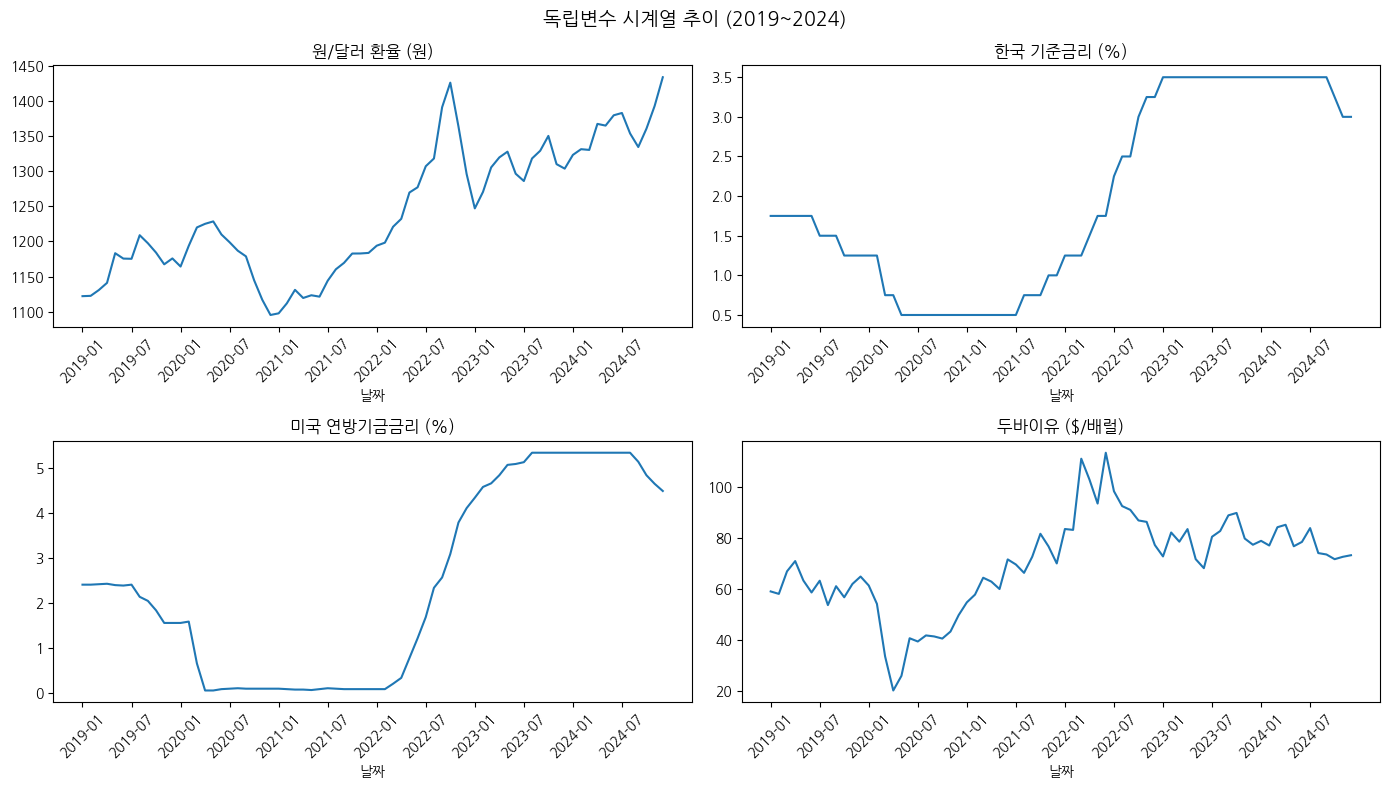

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("독립변수 시계열 추이 (2019~2024)", fontsize=14)

cols = ["원/달러환율", "한국금리", "미국금리", "Dubai"]
titles = ["원/달러 환율 (원)", "한국 기준금리 (%)", "미국 연방기금금리 (%)", "두바이유 ($/배럴)"]

macro_unique = df.drop_duplicates("날짜").sort_values("날짜")

for ax, col, title in zip(axes.flatten(), cols, titles):
    ax.plot(macro_unique["날짜"].values, macro_unique[col].values)
    ax.set_title(title)
    ax.set_xlabel("날짜")
    
    # x축 라벨 6개월 간격으로만 표시
    ax.set_xticks(macro_unique["날짜"].values[::6])
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

- 환율·미국금리: 2022년부터 급등 시작 → 미국 긴축(제로금리 → 5%대) 시기와 정확히 겹침. 전형적인 강달러 패턴

- 한국금리: 미국보다 인상 폭은 작지만(0.5~3.5%) 비슷한 타이밍에 움직임. 한미 금리차 벌어지는 구간이 보임.

- 두바이유: 2020년 코로나로 급락(20달러대) → 2022년 러-우 전쟁으로 급등(110달러대) → 이후 하향 안정화. 지정학적 이벤트가 뚜렷하게 나타남.

3. 충격유형별 월평균 수출금액 비교

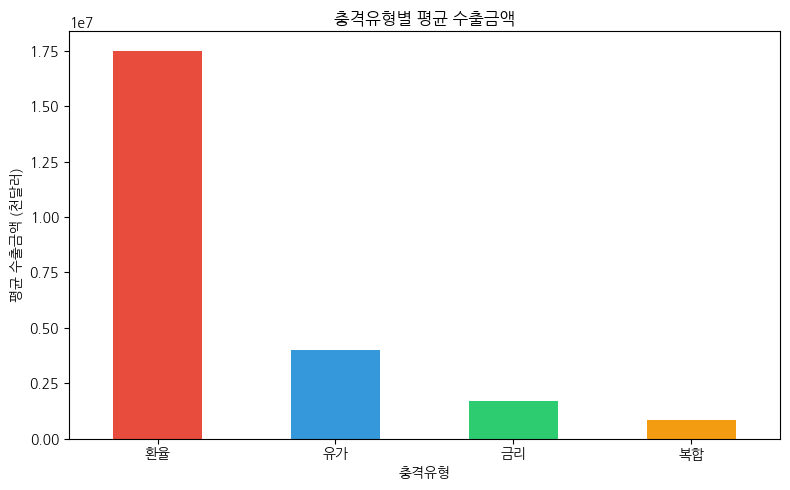

In [40]:
shock_export = df.groupby("충격유형")["수출금액"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
shock_export.plot(kind="bar", color=["#e74c3c", "#3498db", "#2ecc71", "#f39c12"])
plt.title("충격유형별 평균 수출금액")
plt.xlabel("충격유형")
plt.ylabel("평균 수출금액 (천달러)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [41]:
# 충격유형별로 어떤 품목들이 들어있는지 확인
for shock in df["충격유형"].unique():
    items = df[df["충격유형"] == shock]["품목명"].unique()
    print(f"[{shock}] {len(items)}개 품목: {items[:5]}...")

[금리] 10개 품목: ['열연강판' '냉연강판' '강관' '불도저굴착기' '스크레이퍼']...
[복합] 10개 품목: ['항생제' '의약품기타' '반도체제조장비' '반도체공정장비' '리튬이온이차전지']...
[유가] 15개 품목: ['경유등유' '기타석유제품' 'LPG액화' 'LNG액화' '에틸렌']...
[환율] 15개 품목: ['통신기기부품' '기타통신기기' '평판디스플레이' '반도체_메모리' '반도체_비메모리']...


- 위 그래프는 '환율민감 품목군(반도체 등)이 원래 수출 규모가 크다'는 것을 보여줌.
-> 정규화하면 품목 규모 차이가 사라지고, 진짜 충격유형별 변동 패턴을 비교 가능
- ① 품목 규모 차이를 제거하고 "변동성"을 비교

In [42]:
# 충격유형별 수출금액 변동계수(CV) 비교 — 규모 아니라 변동성 확인
shock_cv = df.groupby("충격유형")["수출금액"].agg(["mean", "std"])
shock_cv["변동계수"] = shock_cv["std"] / shock_cv["mean"]
print(shock_cv)

              mean           std      변동계수
충격유형                                      
금리    1.689494e+06  1.514651e+07  8.965115
복합    8.293531e+05  6.558115e+06  7.907507
유가    4.014003e+06  1.958968e+07  4.880335
환율    1.751333e+07  9.156199e+07  5.228131


- ② 품목별로 정규화(표준화) 후 충격유형별 비교

충격유형
환율    0.033394
유가    0.027149
금리    0.025315
복합    0.014812
Name: 수출금액_정규화, dtype: float64


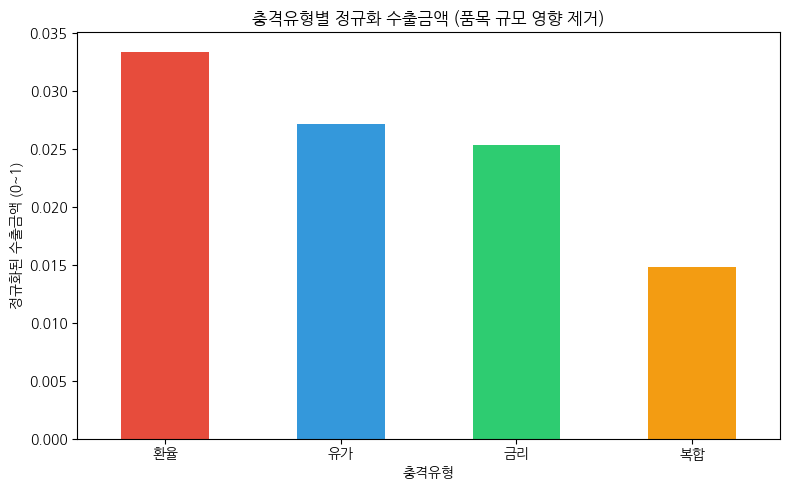

In [43]:
# 품목별로 수출금액을 0~1로 정규화한 뒤 충격유형별 평균 비교
df["수출금액_정규화"] = df.groupby("품목명")["수출금액"].transform(
    lambda x: (x - x.min()) / (x.max() - x.min()) if x.max() > x.min() else 0
)

shock_normalized = df.groupby("충격유형")["수출금액_정규화"].mean().sort_values(ascending=False)
print(shock_normalized)

plt.figure(figsize=(8, 5))
shock_normalized.plot(kind="bar", color=["#e74c3c", "#3498db", "#2ecc71", "#f39c12"])
plt.title("충격유형별 정규화 수출금액 (품목 규모 영향 제거)")
plt.ylabel("정규화된 수출금액 (0~1)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

결과 잘 나왔어요! 근데 숫자가 전부 0.01~0.03 사이로 굉장히 낮다는 점을 먼저 짚어볼게요.

왜 이렇게 낮게 나왔을까?

정규화 공식이 (x - min) / (max - min)인데, 아까 확인했듯이 수출금액에 0인 달이 굉장히 많아요 (중앙값이 2,000이었죠). 그러다 보니:

min은 대부분 0
max는 코로나·전쟁 같은 특정 시기 폭발적 수출 몇 달 값
나머지 대부분 달은 이 극단적인 max에 비해 작아서 0.0X 대로 눌림

즉 "평소엔 낮다가 특정 시기에만 확 튀는" 패턴이라 정규화값이 전반적으로 낮게 나온 거예요. 이 자체는 문제없고, 오히려 의미 있는 신호예요.

해석

그래도 환율(0.033) > 유가(0.027) > 금리(0.025) > 복합(0.015) 순서는 유효해요.

환율 민감 품목(반도체·디스플레이 등) 이 상대적으로 자기 역대 최대치에 더 자주 근접 → 환율 변화에 수출이 더 민감하게 반응한다고 해석 가능
복합충격 그룹이 가장 낮음 → 여러 충격이 겹치는 품목(의약품, 반도체장비 등)은 오히려 극단적 스파이크가 적고 안정적으로 유지되는 걸 수도 있어요

### 이상치?

In [44]:
# 이상치가 "언제" 발생했는지 확인 (삭제 X, 파악만)
import numpy as np

Q1 = df["수출금액"].quantile(0.25)
Q3 = df["수출금액"].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR

outliers = df[df["수출금액"] > upper]
print(f"이상치 개수: {len(outliers)} / 전체: {len(df)}")
print(outliers["날짜"].value_counts().head(10))  # 어느 시기에 몰려있는지
print(outliers["품목명"].value_counts().head(10))  # 어떤 품목에 몰려있는지

이상치 개수: 17555 / 전체: 90000
날짜
2019-01    273
2021-12    273
2019-07    272
2019-04    269
2019-03    267
2021-10    266
2021-07    262
2020-03    261
2019-06    259
2022-03    258
Name: count, dtype: int64
품목명
화장품기타              1301
반도체_메모리            1280
기타집적회로             1174
폴리프로필렌             1143
반도체_비메모리           1023
승용차_1500~3000cc     908
자동차변속기              900
폴리에틸렌고밀도            782
승용차_1000~1500cc     777
자동차구동축              744
Name: count, dtype: int64


이상치가 시기별로 고르게 분포되어 있어요 (특정 충격 시기에 몰려있지 않음). 이건 이상치가 "복합충격 사건"이라기보다, 원래 규모가 큰 품목(반도체, 화장품, 자동차 등)이 꾸준히 높은 값을 내는 것이라는 뜻이에요. 품목명 리스트 보면 확실해요 — 화장품, 반도체, 폴리프로필렌, 자동차 부품처럼 한국의 주력 수출품들이 그대로 나와요.

→ 결론: 이 "이상치"는 삭제하면 안 되는 정상적인 대형 수출 품목들이에요. IQR 기준 이상치 = 실제 통계적 특이값이 아니라 그냥 품목 규모 차이인 거죠.

In [45]:
zero_ratio = (df["수출금액"] == 0).mean()
print(f"수출금액 0인 비율: {zero_ratio:.1%}")

# 품목별로 0 비율이 다른지 확인
zero_by_item = df.groupby("품목명")["수출금액"].apply(lambda x: (x == 0).mean()).sort_values(ascending=False)
print(zero_by_item.head(10))

수출금액 0인 비율: 44.2%
품목명
PET        1.000000
냉동선        0.997222
항공기        0.983889
LPG액화      0.977222
LNG액화      0.973333
탱커         0.901111
선박기타       0.877222
기타기초유분     0.792778
반도체공정장비    0.776667
에틸렌기타      0.768333
Name: 수출금액, dtype: float64


-> 데이터 오류가 아니라 "구조적 0"이에요. 선박·항공기는 원래 매달 거래가 없고 특정 시점에 몰아서 수출되는 품목 특성이에요. PET처럼 특정 국가엔 애초에 수출 자체가 없는 조합도 정상이고요.

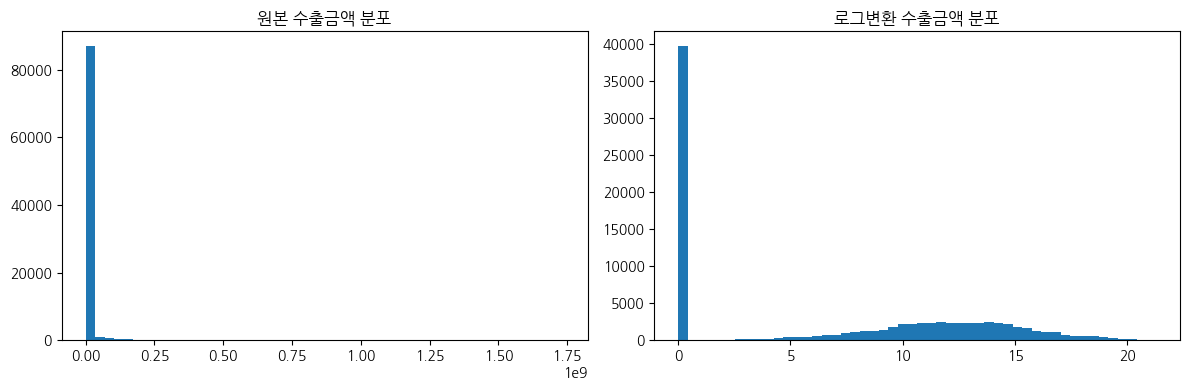

In [46]:
import numpy as np

# 로그 변환 (0값 있어서 log1p 사용)
df["수출금액_log"] = np.log1p(df["수출금액"])

# 분포 비교
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["수출금액"], bins=50)
axes[0].set_title("원본 수출금액 분포")
axes[1].hist(df["수출금액_log"], bins=50)
axes[1].set_title("로그변환 수출금액 분포")
plt.tight_layout()
plt.show()

4. 시기별(코로나/3고위기 등) 비교 분석

In [48]:
# 날짜 컬럼을 Period로 변환
df_final["날짜"] = pd.to_datetime(df_final["날짜"]).dt.to_period("M")

def get_period(date):
    if date <= pd.Period("2020-06", "M"):
        return "코로나 충격기"
    elif date <= pd.Period("2021-12", "M"):
        return "회복기"
    elif date <= pd.Period("2022-12", "M"):
        return "3고위기(고금리·고환율·고유가)"
    else:
        return "안정화기"

df_final["시기"] = df_final["날짜"].apply(get_period)

print(df_final["날짜"].dtype)   # period[M] 확인
print(df_final["시기"].value_counts())

period[M]
시기
안정화기                 30000
회복기                  22500
코로나 충격기              21250
3고위기(고금리·고환율·고유가)    15000
Name: count, dtype: int64


시기
코로나 충격기              7.115239
회복기                  6.935378
3고위기(고금리·고환율·고유가)    6.491610
안정화기                 6.441032
Name: 수출금액_log, dtype: float64


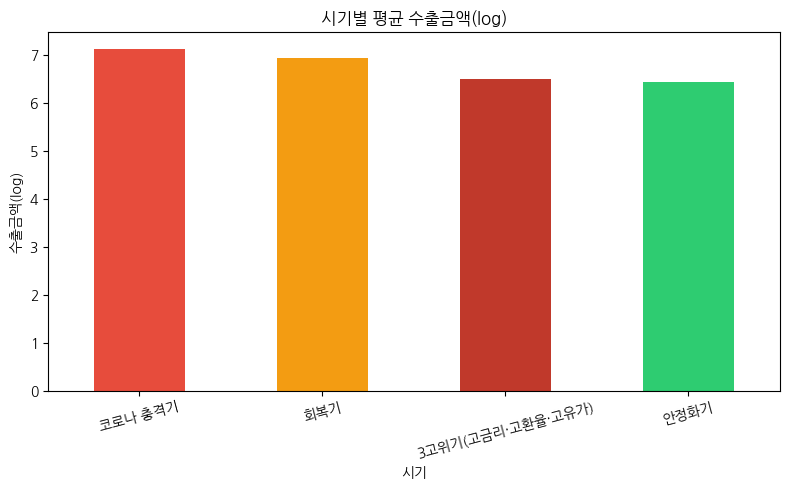

충격유형                     금리        복합        유가        환율
시기                                                       
코로나 충격기            5.375520  6.492102  6.465252  9.340462
회복기                5.156824  6.559881  6.424969  8.881823
3고위기(고금리·고환율·고유가)  5.274632  3.275600  6.456318  9.482227
안정화기               5.123068  3.384442  6.648281  9.150152


In [49]:
# 시기별 평균 수출금액(log)
period_export = df_final.groupby("시기")["수출금액_log"].mean().reindex(
    ["코로나 충격기", "회복기", "3고위기(고금리·고환율·고유가)", "안정화기"]
)
print(period_export)

# 시각화
plt.figure(figsize=(8, 5))
period_export.plot(kind="bar", color=["#e74c3c", "#f39c12", "#c0392b", "#2ecc71"])
plt.title("시기별 평균 수출금액(log)")
plt.ylabel("수출금액(log)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# 시기별 x 충격유형별 교차분석
period_shock = df_final.groupby(["시기", "충격유형"])["수출금액_log"].mean().unstack()
period_shock = period_shock.reindex(["코로나 충격기", "회복기", "3고위기(고금리·고환율·고유가)", "안정화기"])
print(period_shock)

<Figure size 1000x600 with 0 Axes>

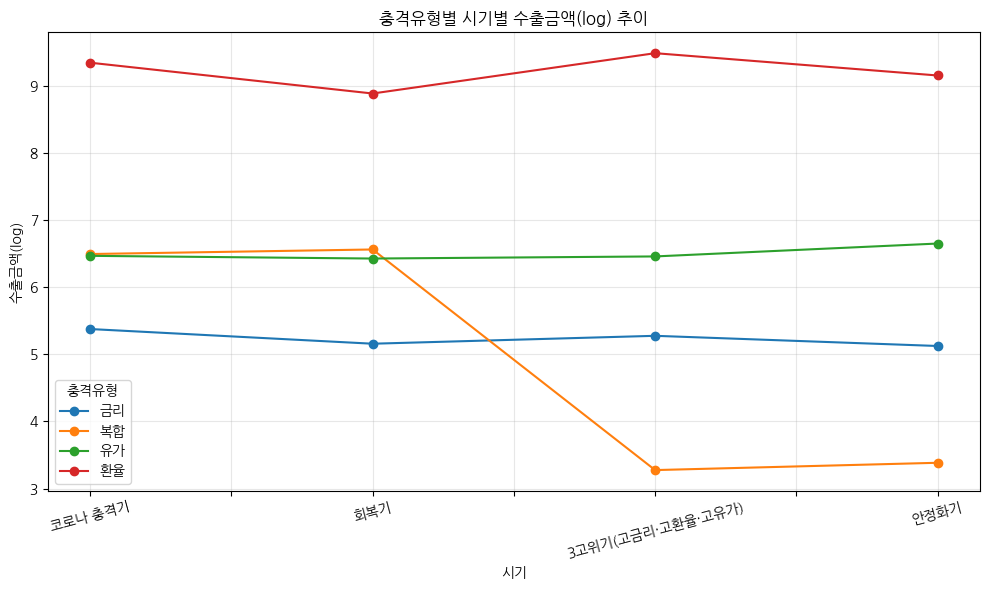

In [50]:
# 시각화
plt.figure(figsize=(10, 6))
period_shock_ordered = period_shock.reindex(["코로나 충격기", "회복기", "3고위기(고금리·고환율·고유가)", "안정화기"])
period_shock_ordered.plot(kind="line", marker="o", figsize=(10,6))
plt.title("충격유형별 시기별 수출금액(log) 추이")
plt.ylabel("수출금액(log)")
plt.xticks(rotation=15)
plt.legend(title="충격유형")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 상관관계 분석

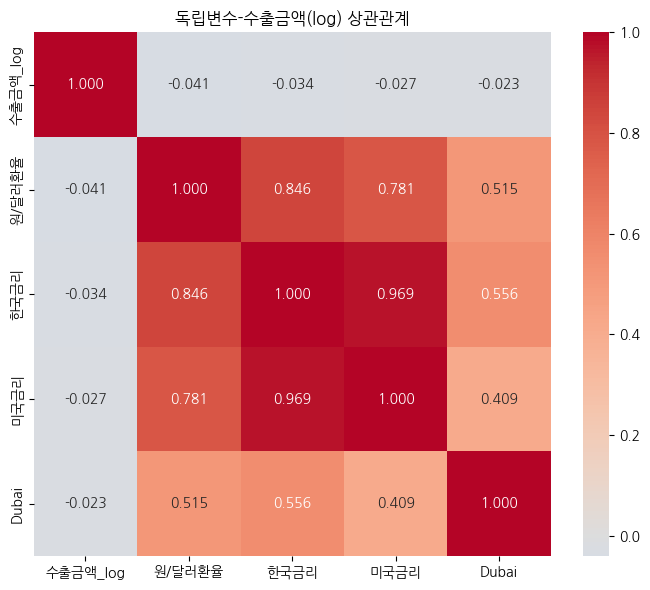

수출금액_log    1.000000
Dubai      -0.022917
미국금리       -0.027455
한국금리       -0.033573
원/달러환율     -0.041257
Name: 수출금액_log, dtype: float64


In [15]:
import seaborn as sns

# 로그변환된 수출금액으로 상관관계 분석
corr_cols = ["수출금액_log", "원/달러환율", "한국금리", "미국금리", "Dubai"]
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, fmt=".3f")
plt.title("독립변수-수출금액(log) 상관관계")
plt.tight_layout()
plt.show()

print(corr_matrix["수출금액_log"].sort_values(ascending=False))

1. 품목/충격유형별로 나눠서 상관관계 다시 보기

In [16]:
# 충격유형별 상관관계 비교
for shock in df["충격유형"].unique():
    sub = df[df["충격유형"] == shock]
    corr = sub[corr_cols].corr()["수출금액_log"].drop("수출금액_log")
    print(f"\n[{shock}]")
    print(corr.sort_values(ascending=False))


[금리]
Dubai     0.001566
한국금리     -0.005217
미국금리     -0.005221
원/달러환율   -0.015325
Name: 수출금액_log, dtype: float64

[복합]
미국금리     -0.193784
Dubai    -0.196865
한국금리     -0.229738
원/달러환율   -0.234151
Name: 수출금액_log, dtype: float64

[유가]
미국금리      0.014746
Dubai     0.013762
한국금리      0.013481
원/달러환율    0.008128
Name: 수출금액_log, dtype: float64

[환율]
Dubai     0.025409
한국금리      0.013563
미국금리      0.011433
원/달러환율    0.002125
Name: 수출금액_log, dtype: float64


복합충격 그룹만 상관관계가 뚜렷하게 나와요 (다른 그룹은 0.001~0.03 수준으로 사실상 없음). 그리고 전부 음의 상관관계예요.

해석하면: 환율·금리·유가가 오를 때 복합충격 품목(반도체장비, 의약품, 이차전지 등)의 수출이 오히려 줄어드는 경향이 있다는 뜻이에요. 이 품목들이 여러 충격에 동시에 취약하다는 신청서의 가설과 방향이 맞아요.

금리·유가·환율 단일충격 그룹은 왜 거의 0일까?
아마 이 그룹들은 단일 변수보다 다른 요인(글로벌 수요, 계약 시점) 의 영향이 더 크거나, 각 품목 안에서도 반응이 엇갈려서(어떤 국가는 +, 어떤 국가는 -) 평균에서 상쇄됐을 가능성이 커요.

2. 다중공선성 확인(VIF)

In [19]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = df[["원/달러환율", "한국금리", "미국금리", "Dubai"]].dropna()
vif = pd.DataFrame()
vif["변수"] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif)

       변수         VIF
0  원/달러환율   20.534007
1    한국금리  121.250930
2    미국금리   63.051240
3   Dubai   36.884713


VIF 10 넘으면 문제인데, 전부 20~121이에요. 이 상태로 회귀분석하면 계수가 왜곡돼서 신뢰할 수 없어요. 특히 한국금리·미국금리가 거의 같이 움직이니(상관계수 0.969) 회귀식이 "둘 중 뭐가 진짜 원인인지" 구분을 못 해요.

해결 방법 — 이렇게 하는 걸 추천해요

1차분(변화량)으로 변환하는 게 가장 효과적이에요. 수준값 대신 "전월 대비 변화량"을 쓰면 다중공선성이 크게 줄어들어요:

In [21]:
# 독립변수를 전월 대비 변화율(%)로 변환
macro_diff = X_df .copy()
for col in ["원/달러환율", "한국금리", "미국금리", "Dubai"]:
    macro_diff[col + "_변화율"] = macro_diff[col].pct_change() * 100

macro_diff = macro_diff.dropna()

# VIF 재확인
from statsmodels.stats.outliers_influence import variance_inflation_factor

diff_cols = ["원/달러환율_변화율", "한국금리_변화율", "미국금리_변화율", "Dubai_변화율"]
X_diff = macro_diff[diff_cols].dropna()

vif_diff = pd.DataFrame()
vif_diff["변수"] = X_diff.columns
vif_diff["VIF"] = [variance_inflation_factor(X_diff.values, i) for i in range(X_diff.shape[1])]
print(vif_diff)

           변수       VIF
0  원/달러환율_변화율  1.034888
1    한국금리_변화율  1.131442
2    미국금리_변화율  1.427766
3   Dubai_변화율  1.289773


In [22]:
# 변화율 데이터 & 종속변수 병합
macro_diff_final = macro_diff[["날짜"] + diff_cols].copy()

df_final = df.merge(macro_diff_final, on="날짜", how="inner")

print(df_final.shape)
print(df_final[["날짜"] + diff_cols].head(5))

(88750, 21)
        날짜  원/달러환율_변화율  한국금리_변화율  미국금리_변화율  Dubai_변화율
0  2019-02    0.039845       0.0  0.000000  -1.622638
1  2019-03    0.737045       0.0  0.416667  15.161934
2  2019-04    0.904733       0.0  0.414938   5.979599
3  2019-05    3.710984       0.0 -1.239669 -10.704564
4  2019-06   -0.648589       0.0 -0.418410  -7.360541


## 회귀분석
- 종속변수: 수출금액_log (또는 로그 변화율)
- 독립변수: 원/달러환율_변화율, 한국금리_변화율, 미국금리_변화율, Dubai_변화율 

In [24]:
import statsmodels.api as sm

# 결측치 제거 (변화율은 첫 달이 NaN)
reg_data = df_final.dropna(subset=diff_cols + ["수출금액_log"])

X = reg_data[diff_cols]
y = reg_data["수출금액_log"]

X = sm.add_constant(X)  # 절편 추가

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:               수출금액_log   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     3.953
Date:                Mon, 17 Aug 2026   Prob (F-statistic):            0.00328
Time:                        16:11:01   Log-Likelihood:            -2.9258e+05
No. Observations:               88750   AIC:                         5.852e+05
Df Residuals:                   88745   BIC:                         5.852e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.7506      0.023    296.568      0.0

R-squared가 0.000으로 거의 설명 못한다고 나옴. 지금 모델은 "전체 데이터를 다 뭉쳐서" 보면 환율·금리·유가 변화가 수출에 미치는 영향이 통계적으로 거의 없다고 나온 것.  
충격 유형별로 나눠서 회귀분석해보기

In [25]:
# 충격유형별로 나눠서 회귀분석
for shock in df_final["충격유형"].unique():
    sub = df_final[df_final["충격유형"] == shock].dropna(subset=diff_cols + ["수출금액_log"])
    
    X = sm.add_constant(sub[diff_cols])
    y = sub["수출금액_log"]
    
    model = sm.OLS(y, X).fit()
    
    print(f"\n{'='*50}")
    print(f"[{shock}] R² = {model.rsquared:.4f}")
    print(model.params)
    print(model.pvalues)


[금리] R² = 0.0002
const         5.220971
원/달러환율_변화율    0.000162
한국금리_변화율     -0.006094
미국금리_변화율      0.001779
Dubai_변화율    -0.004540
dtype: float64
const         0.000000
원/달러환율_변화율    0.994843
한국금리_변화율      0.156869
미국금리_변화율      0.321164
Dubai_변화율     0.245409
dtype: float64

[복합] R² = 0.0112
const         5.029851
원/달러환율_변화율   -0.025569
한국금리_변화율     -0.011616
미국금리_변화율     -0.019244
Dubai_변화율     0.024189
dtype: float64
const         0.000000e+00
원/달러환율_변화율    2.641494e-01
한국금리_변화율      3.173817e-03
미국금리_변화율      1.151317e-31
Dubai_변화율     1.361347e-11
dtype: float64

[유가] R² = 0.0001
const         6.506195e+00
원/달러환율_변화율    2.354654e-02
한국금리_변화율     -7.156779e-07
미국금리_변화율      9.692981e-04
Dubai_변화율    -4.360414e-03
dtype: float64
const         0.000000
원/달러환율_변화율    0.274217
한국금리_변화율      0.999846
미국금리_변화율      0.529811
Dubai_변화율     0.194662
dtype: float64

[환율] R² = 0.0003
const         9.161814
원/달러환율_변화율    0.023794
한국금리_변화율      0.000078
미국금리_변화율      0.002991
Dubai_변화율    -0.

복합만 유의미, 다른 그룹들은 왜 안 나올까?

금리, 유가, 환율 그룹은 R²가 0.0001~0.0003으로 사실상 설명력이 없어요.  
가능한 이유:

품목·국가별로 반응이 정반대라서 평균에서 상쇄 (예: 어떤 국가는 환율 오르면 수출 늘고, 어떤 국가는 줄고)
월별 데이터라 시차(lag) 효과를 못 잡음 — 환율 변화가 수출에 반영되기까지 1~2개월 걸릴 수 있음
선형관계가 아닐 수 있음 — 실제로는 비선형적 영향일 가능성

- ① 시차(lag) 넣어보기 — 이번 달 환율이 아니라 지난달 환율이 이번 달 수출에 영향을 주는지

In [26]:
# 시차 변수 만들기
# 품목-국가 조합별로 정렬 후 1개월 시차 생성
df_final = df_final.sort_values(["품목명", "국가명", "날짜"])

for col in diff_cols:
    df_final[col + "_lag1"] = df_final.groupby(["품목명", "국가명"])[col].shift(1)

lag_cols = [col + "_lag1" for col in diff_cols]
print(df_final[["날짜", "품목명", "국가명"] + diff_cols + lag_cols].head(10))

            날짜    품목명  국가명  원/달러환율_변화율   한국금리_변화율   미국금리_변화율  Dubai_변화율  \
40825  2019-02  LNG액화  UAE    0.039845   0.000000   0.000000  -1.622638   
40826  2019-03  LNG액화  UAE    0.737045   0.000000   0.416667  15.161934   
40827  2019-04  LNG액화  UAE    0.904733   0.000000   0.414938   5.979599   
40828  2019-05  LNG액화  UAE    3.710984   0.000000  -1.239669 -10.704564   
40829  2019-06  LNG액화  UAE   -0.648589   0.000000  -0.418410  -7.360541   
40830  2019-07  LNG액화  UAE   -0.026122 -14.285714   0.840336   7.821642   
40831  2019-08  LNG액화  UAE    2.864566   0.000000 -11.250000 -15.055696   
40832  2019-09  LNG액화  UAE   -0.945331   0.000000  -4.225352  13.729195   
40833  2019-10  LNG액화  UAE   -1.120126 -16.666667 -10.294118  -7.079010   
40834  2019-11  LNG액화  UAE   -1.408706   0.000000 -15.300546   9.139860   

       원/달러환율_변화율_lag1  한국금리_변화율_lag1  미국금리_변화율_lag1  Dubai_변화율_lag1  
40825              NaN            NaN            NaN             NaN  
40826         0.039845       0.0

In [29]:
# 시차변수로 회귀분석(충격유형별)
# 이번 달 수출 = 지난달 환율·금리·유가 변화의 영향을 받는지 확인
for shock in df_final["충격유형"].unique():
    sub = df_final[df_final["충격유형"] == shock].dropna(subset=lag_cols + ["수출금액_log"])
    
    X = sm.add_constant(sub[lag_cols])
    y = sub["수출금액_log"]
    
    model = sm.OLS(y, X).fit()
    
    print(f"\n{'='*50}")
    print(f"[{shock}] R² = {model.rsquared:.4f}")
    print(model.params)
    print(model.pvalues)


[유가] R² = 0.0000
const              6.509861
원/달러환율_변화율_lag1   -0.006677
한국금리_변화율_lag1      0.001835
미국금리_변화율_lag1      0.000646
Dubai_변화율_lag1     0.001573
dtype: float64
const              0.000000
원/달러환율_변화율_lag1    0.760003
한국금리_변화율_lag1      0.620262
미국금리_변화율_lag1      0.675963
Dubai_변화율_lag1     0.640265
dtype: float64

[금리] R² = 0.0002
const              5.206905
원/달러환율_변화율_lag1   -0.018071
한국금리_변화율_lag1      0.004316
미국금리_변화율_lag1      0.001373
Dubai_변화율_lag1     0.000339
dtype: float64
const              0.000000
원/달러환율_변화율_lag1    0.476808
한국금리_변화율_lag1      0.315935
미국금리_변화율_lag1      0.444888
Dubai_변화율_lag1     0.930945
dtype: float64

[환율] R² = 0.0005
const              9.139911
원/달러환율_변화율_lag1    0.028466
한국금리_변화율_lag1      0.006103
미국금리_변화율_lag1      0.002707
Dubai_변화율_lag1    -0.001548
dtype: float64
const              0.000000
원/달러환율_변화율_lag1    0.175445
한국금리_변화율_lag1      0.086463
미국금리_변화율_lag1      0.068483
Dubai_변화율_lag1     0.632343
dtype: float64

[복합] R² = 0.011

→ 복합 그룹은 시차 없이도, 시차 있어도 일관되게 유의미함. 그것도 거의 같은 변수(미국금리, Dubai)가 똑같이 유의미하고, 계수 부호도 그대로  
→ 이건 오히려 좋은 신호예요. 복합충격 그룹에서 금리·유가 영향이 "일시적 우연"이 아니라 당월이든 익월이든 꾸준히 나타나는 안정적인 패턴이라는 뜻이거든요. 분석 신뢰도가 높아진 거예요.

나머지 그룹(금리·유가·환율)은 시차를 넣어도 여전히 설명력이 없어요. → 시차 문제가 원인이 아니라, 앞서 얘기했듯 품목별로 반응이 엇갈려서 평균에서 상쇄되는 게 진짜 원인일 가능성이 높아요.

- ② 품목별로 더 세분화 — 금리 그룹 안에서도 철강 vs 기계는 다르게 반응할 수 있음
    - 금리, 유가, 환율 그룹 안에서 품목마다 반응이 다른지 확인하기. 데이터가 너무 적은 품목(20개 미만)은 제외.

In [30]:
results = []

for shock in ["금리", "유가", "환율"]:  # 복합은 이미 확인했으니 제외
    items = df_final[df_final["충격유형"] == shock]["품목명"].unique()
    
    for item in items:
        sub = df_final[(df_final["충격유형"] == shock) & (df_final["품목명"] == item)]
        sub = sub.dropna(subset=diff_cols + ["수출금액_log"])
        
        if len(sub) < 20:  # 데이터 너무 적으면 스킵
            continue
        
        X = sm.add_constant(sub[diff_cols])
        y = sub["수출금액_log"]
        
        model = sm.OLS(y, X).fit()
        
        # 유의미한 변수만 추출 (p < 0.05)
        sig_vars = model.pvalues[1:][model.pvalues[1:] < 0.05].index.tolist()
        
        results.append({
            "충격유형": shock,
            "품목명": item,
            "R2": model.rsquared,
            "유의변수": ", ".join(sig_vars) if sig_vars else "없음",
            "n": len(sub)
        })

result_df = pd.DataFrame(results).sort_values("R2", ascending=False)
print(result_df.to_string(index=False))

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/statsmodels/regression/linear_model.py:1782: RuntimeWarning: invalid value encountered in scalar divide
  return 1 - self.ssr/self.centered_tss


충격유형             품목명       R2                유의변수    n
  환율          통신기기부품 0.047144 미국금리_변화율, Dubai_변화율 1775
  환율          기타통신기기 0.010873            미국금리_변화율 1775
  환율         평판디스플레이 0.007969            한국금리_변화율 1775
  금리          불도저굴착기 0.005328 미국금리_변화율, Dubai_변화율 1775
  유가           LNG액화 0.004213           Dubai_변화율 1775
  유가        폴리에틸렌고밀도 0.003908                  없음 1775
  유가           LPG액화 0.003236            한국금리_변화율 1775
  금리           산업용로봇 0.003179                  없음 1775
  금리            선박기타 0.002917                  없음 1775
  환율          기타집적회로 0.002886                  없음 1775
  유가           화장품기타 0.002530                  없음 1775
  유가          기타석유제품 0.002509                  없음 1775
  유가            경유등유 0.002466                  없음 1775
  유가             PVC 0.002076                  없음 1775
  금리              탱커 0.002031                  없음 1775
  환율         기타자동차부품 0.001815                  없음 1775
  유가            합성염료 0.001706                  없음 1775
  유가      

In [31]:
# R-square 높은 순으로 상위 품목만 따로 보기
# R² 상위 15개 품목
print(result_df.head(15))

# 충격유형별 R² 평균 (그룹 전체 vs 품목별 비교)
print(result_df.groupby("충격유형")["R2"].mean())

   충격유형       품목명        R2                 유의변수     n
38   환율    통신기기부품  0.047144  미국금리_변화율, Dubai_변화율  1775
29   환율    기타통신기기  0.010873             미국금리_변화율  1775
39   환율   평판디스플레이  0.007969             한국금리_변화율  1775
3    금리    불도저굴착기  0.005328  미국금리_변화율, Dubai_변화율  1775
10   유가     LNG액화  0.004213            Dubai_변화율  1775
19   유가  폴리에틸렌고밀도  0.003908                   없음  1775
11   유가     LPG액화  0.003236             한국금리_변화율  1775
4    금리     산업용로봇  0.003179                   없음  1775
5    금리      선박기타  0.002917                   없음  1775
28   환율    기타집적회로  0.002886                   없음  1775
24   유가     화장품기타  0.002530                   없음  1775
16   유가    기타석유제품  0.002509                   없음  1775
14   유가      경유등유  0.002466                   없음  1775
13   유가       PVC  0.002076                   없음  1775
9    금리        탱커  0.002031                   없음  1775
충격유형
금리    0.001800
유가    0.001976
환율    0.005152
Name: R2, dtype: float64


결론적으로 이 데이터셋에서 가장 강하고 일관된 신호는 두 가지예요:

복합충격 품목군(반도체장비·이차전지·의약품 등) → 미국금리·Dubai에 유의미하게 반응
통신기기부품 → 미국금리·Dubai에 상대적으로 강하게 반응 (개별 품목 중 최고 R²)

- 통신기기부품 국가별 세분석

In [51]:
comm = df_final[df_final["품목명"] == "통신기기부품"]

country_results = []
for country in comm["국가명"].unique():
    sub = comm[comm["국가명"] == country].dropna(subset=diff_cols + ["수출금액_log"])
    if len(sub) < 20:
        continue
    X = sm.add_constant(sub[diff_cols])
    y = sub["수출금액_log"]
    model = sm.OLS(y, X).fit()
    sig_vars = model.pvalues[1:][model.pvalues[1:] < 0.05].index.tolist()
    country_results.append({
        "국가명": country, "R2": model.rsquared,
        "유의변수": ", ".join(sig_vars) if sig_vars else "없음", "n": len(sub)
    })

comm_result = pd.DataFrame(country_results).sort_values("R2", ascending=False)
print(comm_result.to_string(index=False))

  국가명       R2                  유의변수  n
 네덜란드 0.267038              미국금리_변화율 71
  멕시코 0.200133   미국금리_변화율, Dubai_변화율 71
   미국 0.179733              미국금리_변화율 71
   중국 0.153156   미국금리_변화율, Dubai_변화율 71
인도네시아 0.136692                    없음 71
   일본 0.123762                    없음 71
  UAE 0.122849              미국금리_변화율 71
   홍콩 0.118672 원/달러환율_변화율, Dubai_변화율 71
  브라질 0.114151              미국금리_변화율 71
말레이시아 0.113962            원/달러환율_변화율 71
  베트남 0.112811                    없음 71
   대만 0.109418              미국금리_변화율 71
   호주 0.109131                    없음 71
  사우디 0.097283              미국금리_변화율 71
   태국 0.090721              미국금리_변화율 71
   영국 0.087797              한국금리_변화율 71
  러시아 0.086336            원/달러환율_변화율 71
  필리핀 0.074825                    없음 71
  폴란드 0.074754                    없음 71
 이탈리아 0.066528                    없음 71
   인도 0.059548                    없음 71
  캐나다 0.058353                    없음 71
방글라데시 0.044817                    없음 71
   독일 0.035029                    없음 71


국가별로 쪼개니까 훨씬 강한 신호가 나왔어요! 아까 전체 통신기기부품 R²가 0.047이었는데, 국가별로는 이렇게 차이가 커요.

핵심 발견

상위 4개국은 R²가 0.15~0.27로 확연히 높아요:

국가	R²	유의변수
네덜란드	0.267	미국금리
멕시코	0.200	미국금리, Dubai
미국	0.180	미국금리
중국	0.153	미국금리, Dubai

공통점이 뚜렷해요. 상위 4개국 모두 미국금리가 유의미해요. 그리고 이 4개국은 전부 글로벌 전자제품·반도체 공급망의 핵심 거점이에요.

네덜란드 → ASML 등 반도체 장비 허브
멕시코 → 북미 전자제품 조립 기지 (니어쇼어링)
미국 → 최종 수요처이자 기술 공급망 핵심
중국 → 전자제품 조립·최종 소비 시장

즉 통신기기부품 수출이 미국금리에 민감하게 반응하는 이유가, 이 4개국이 미국 중심 글로벌 전자산업 공급망에 속해있어서 미국 통화정책 영향을 직접 받기 때문이라는 해석이 가능해요. 이건 상당히 설득력 있는 스토리예요.

반면 하위권(싱가포르 0.016, 독일 0.035, 방글라데시 0.045)은 거의 반응이 없어요. → 이 나라들은 공급망상 위치가 다르거나 통신기기부품 교역 비중 자체가 작을 가능성이 있어요.

### 충격유형 사전 라벨링 검증

In [57]:
# ------------------------------------------------------------
# STEP 1. 품목별로 4개 거시변수의 "회귀계수 + 유의성"을 전부 추출
#   - 기존 Cell 50은 금리/유가/환율만 돌렸는데, 복합도 포함해서
#     전체 품목에 대해 동일한 기준으로 계수를 뽑습니다.
# ------------------------------------------------------------
coef_results = []

for shock in df_final["충격유형"].unique():
    items = df_final[df_final["충격유형"] == shock]["품목명"].unique()
    for item in items:
        sub = df_final[
            (df_final["충격유형"] == shock) & (df_final["품목명"] == item)
        ].dropna(subset=diff_cols + ["수출금액_log"])

        if len(sub) < 20:  # 데이터 너무 적은 품목 제외 (기존 기준과 동일)
            continue

        X = sm.add_constant(sub[diff_cols])
        y = sub["수출금액_log"]
        model = sm.OLS(y, X).fit()

        row = {"충격유형_라벨": shock, "품목명": item, "R2": model.rsquared, "n": len(sub)}
        for col in diff_cols:
            row[f"{col}_계수"] = model.params.get(col, np.nan)
            row[f"{col}_pvalue"] = model.pvalues.get(col, np.nan)
        coef_results.append(row)

coef_df = pd.DataFrame(coef_results)
print(f"분석 대상 품목 수: {len(coef_df)}")
print(coef_df.head())

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/statsmodels/regression/linear_model.py:1782: RuntimeWarning: invalid value encountered in scalar divide
  return 1 - self.ssr/self.centered_tss


분석 대상 품목 수: 50
  충격유형_라벨    품목명        R2     n  원/달러환율_변화율_계수  원/달러환율_변화율_pvalue  \
0      유가  LNG액화  0.004213  1775      -0.003985           0.404022   
1      유가  LPG액화  0.003236  1775      -0.026931           0.290515   
2      유가    PET       NaN  1775       0.000000                NaN   
3      유가    PVC  0.002076  1775       0.083633           0.213701   
4      유가   경유등유  0.002466  1775       0.037761           0.716351   

   한국금리_변화율_계수  한국금리_변화율_pvalue  미국금리_변화율_계수  미국금리_변화율_pvalue  Dubai_변화율_계수  \
0     0.000583         0.477654     0.000123         0.719440      0.001471   
1     0.008671         0.047852    -0.000470         0.796684      0.003213   
2     0.000000              NaN     0.000000              NaN      0.000000   
3     0.000609         0.958017     0.001572         0.744129     -0.013131   
4     0.024991         0.162030     0.000547         0.941403     -0.019220   

   Dubai_변화율_pvalue  
0          0.048616  
1          0.419287  
2               NaN  
3

In [58]:
# ------------------------------------------------------------
# STEP 2. "라벨이 맞다면 가장 크게 반응해야 할 변수"를 정의
#   - 라벨 ↔ 예상 변수 매핑. 필요시 이 딕셔너리만 조정하면 됩니다.
# ------------------------------------------------------------
label_to_expected_var = {
    "환율": ["원/달러환율_변화율"],
    "금리": ["한국금리_변화율", "미국금리_변화율"],  # 둘 중 하나라도 걸리면 OK로 처리
    "유가": ["Dubai_변화율"],
    "복합": diff_cols,  # 복합은 여러 변수 중 하나 이상 유의미하면 OK
}

def get_top_variable(row, diff_cols):
    """이 품목에서 절대값 기준으로 가장 크게 반응한 변수 (p<0.1 유의한 것 중)"""
    sig_vars = {
        col: abs(row[f"{col}_계수"])
        for col in diff_cols
        if row[f"{col}_pvalue"] < 0.1  # 느슨한 기준(10%)으로 일단 확인
    }
    if not sig_vars:
        return None  # 유의미한 변수가 하나도 없음
    return max(sig_vars, key=sig_vars.get)

coef_df["실제_최대반응변수"] = coef_df.apply(lambda r: get_top_variable(r, diff_cols), axis=1)

def label_matches(row):
    expected = label_to_expected_var.get(row["충격유형_라벨"], [])
    if row["실제_최대반응변수"] is None:
        return "유의변수 없음"
    return "일치" if row["실제_최대반응변수"] in expected else "불일치"

coef_df["라벨_검증결과"] = coef_df.apply(label_matches, axis=1)

In [59]:
# ------------------------------------------------------------
# STEP 3. 라벨별 일치율 요약
# ------------------------------------------------------------
match_summary = pd.crosstab(coef_df["충격유형_라벨"], coef_df["라벨_검증결과"], normalize="index") * 100
print("\n=== 충격유형 라벨별 검증 결과 (%) ===")
print(match_summary.round(1))

print("\n=== 불일치 품목 목록 (라벨을 다시 봐야 할 후보) ===")
mismatch = coef_df[coef_df["라벨_검증결과"] == "불일치"][
    ["충격유형_라벨", "품목명", "실제_최대반응변수", "R2"]
].sort_values("R2", ascending=False)
print(mismatch)


=== 충격유형 라벨별 검증 결과 (%) ===
라벨_검증결과   불일치  유의변수 없음    일치
충격유형_라벨                     
금리       20.0     80.0   0.0
복합        0.0     30.0  70.0
유가       20.0     66.7  13.3
환율       20.0     80.0   0.0

=== 불일치 품목 목록 (라벨을 다시 봐야 할 후보) ===
   충격유형_라벨      품목명  실제_최대반응변수        R2
38      환율   통신기기부품  Dubai_변화율  0.047144
29      환율   기타통신기기   미국금리_변화율  0.010873
39      환율  평판디스플레이   한국금리_변화율  0.007969
18      금리   불도저굴착기  Dubai_변화율  0.005328
1       유가    LPG액화   한국금리_변화율  0.003236
20      금리     선박기타  Dubai_변화율  0.002917
14      유가    화장품기타   미국금리_변화율  0.002530
6       유가   기타석유제품   한국금리_변화율  0.002509



=== 사전 라벨 vs 데이터 기반 군집 교차표 ===
군집       0  1  2  3
충격유형_라벨            
금리       4  4  0  2
복합       2  4  3  1
유가       1  9  0  5
환율       2  7  0  6

Adjusted Rand Index (라벨-군집 일치도, 0=무관 ~ 1=완전일치): 0.026


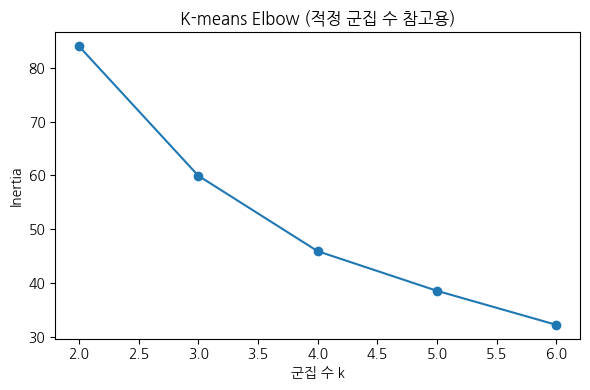

In [60]:
# ------------------------------------------------------------
# STEP 4. 라벨과 무관하게 데이터가 스스로 그룹을 나누면? (K-means)
#   - 4개 계수를 표준화한 뒤 군집화 → 사전 라벨과 비교
# ------------------------------------------------------------
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

coef_cols = [f"{col}_계수" for col in diff_cols]
cluster_data = coef_df.dropna(subset=coef_cols).copy()

X_scaled = StandardScaler().fit_transform(cluster_data[coef_cols])

# 라벨이 4종류(금리/유가/환율/복합)이므로 일단 k=4로 시작
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_data["군집"] = kmeans.fit_predict(X_scaled)

print("\n=== 사전 라벨 vs 데이터 기반 군집 교차표 ===")
print(pd.crosstab(cluster_data["충격유형_라벨"], cluster_data["군집"]))

ari = adjusted_rand_score(cluster_data["충격유형_라벨"], cluster_data["군집"])
print(f"\nAdjusted Rand Index (라벨-군집 일치도, 0=무관 ~ 1=완전일치): {ari:.3f}")

# 참고: 군집 개수를 바꿔가며(k=2~6) 확인해보고 싶다면 아래 elbow도 같이 확인
inertias = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertias.append(km.inertia_)

import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.plot(range(2, 7), inertias, marker="o")
plt.title("K-means Elbow (적정 군집 수 참고용)")
plt.xlabel("군집 수 k")
plt.ylabel("Inertia")
plt.tight_layout()
plt.show()

# ============================================================
# 해석 가이드
# ============================================================
# - match_summary 표에서 "복합" 라벨의 일치율이 가장 높게 나올 가능성이 큽니다
#   (이미 회귀분석에서 복합충격 그룹만 유의미했으므로).
#   금리/유가/환율 라벨의 불일치율이 높게 나온다면, 그 라벨들이
#   "그룹 내 반응이 엇갈려서 평균이 상쇄된다"는 이전 가설을 뒷받침하는
#   근거가 됩니다.
#
# - ARI가 0에 가깝다면: 사전 라벨과 실제 데이터 패턴이 거의 무관하다는 뜻
#   → 발표 자료에서 "라벨은 가설로 사용했고, 사후 검증 결과 A/B/C 품목군은
#      재분류가 필요함을 확인했다"는 스토리로 오히려 강점이 됩니다.
#   ARI가 높다면: 라벨링이 실제로 타당했다는 근거이므로 그대로 신뢰하고
#   진행하면 됩니다.
#
# - mismatch 표에서 R2가 높은데 라벨이 불일치인 품목이 있다면
#   (예: 통신기기부품처럼) 그 품목이 "숨겨진 신호"를 가진 케이스이니
#   개별 스토리로 다뤄볼 가치가 있습니다.

- 전자공급망 후보군(기타통신기기, 평판디스플레이)과 중장비/조선 후보군(불도저굴착기, 선박기타) 국가별 세분석

In [65]:
def analyze_by_country(item_name, df_final, diff_cols, min_n=20):
    """특정 품목을 국가별로 쪼개서 회귀분석하고 결과를 반환"""
    item_data = df_final[df_final["품목명"] == item_name]
    country_results = []

    for country in item_data["국가명"].unique():
        sub = item_data[item_data["국가명"] == country].dropna(
            subset=diff_cols + ["수출금액_log"]
        )
        if len(sub) < min_n:
            continue

        X = sm.add_constant(sub[diff_cols])
        y = sub["수출금액_log"]
        model = sm.OLS(y, X).fit()

        row = {"품목명": item_name, "국가명": country, "R2": model.rsquared, "n": len(sub)}
        # 유의한(p<0.1) 변수만 문자열로 정리
        sig_vars = [
            col for col in diff_cols if model.pvalues.get(col, 1) < 0.1
        ]
        row["유의변수"] = ", ".join(sig_vars) if sig_vars else "-"
        for col in diff_cols:
            row[f"{col}_계수"] = model.params.get(col, None)
            row[f"{col}_pvalue"] = model.pvalues.get(col, None)
        country_results.append(row)

    return pd.DataFrame(country_results).sort_values("R2", ascending=False)

In [66]:
# ------------------------------------------------------------
# 그룹 1: 전자·반도체 공급망 후보군 (환율 라벨이었으나 실제론 다른 변수 반응)
# ------------------------------------------------------------
electronics_group = ["통신기기부품", "기타통신기기", "평판디스플레이"]

print("=" * 60)
print("그룹 1: 전자·반도체 공급망 후보군")
print("=" * 60)

electronics_results = []
for item in electronics_group:
    result = analyze_by_country(item, df_final, diff_cols)
    electronics_results.append(result)
    print(f"\n--- {item} (국가별 상위 5개) ---")
    print(result[["국가명", "R2", "n", "유의변수"]].head(5).to_string(index=False))

electronics_df = pd.concat(electronics_results, ignore_index=True)


# ------------------------------------------------------------
# 그룹 2: 중장비·조선 후보군 (금리 라벨이었으나 실제론 Dubai 반응)
# ------------------------------------------------------------
heavy_industry_group = ["불도저굴착기", "선박기타"]

print("\n" + "=" * 60)
print("그룹 2: 중장비·조선 후보군")
print("=" * 60)

heavy_results = []
for item in heavy_industry_group:
    result = analyze_by_country(item, df_final, diff_cols)
    heavy_results.append(result)
    print(f"\n--- {item} (국가별 상위 5개) ---")
    print(result[["국가명", "R2", "n", "유의변수"]].head(5).to_string(index=False))

heavy_df = pd.concat(heavy_results, ignore_index=True)


# ------------------------------------------------------------
# 요약: R2가 특히 높게 나온 국가 (전체 통합 상위 10개)
#   - 통신기기부품 국가별 분석 때처럼, 이 상위권 국가들이
#     공급망상 공통점(반도체 허브 / 자원부국 등)을 갖는지 직접 확인해보세요.
# ------------------------------------------------------------
all_country_results = pd.concat([electronics_df, heavy_df], ignore_index=True)
print("\n" + "=" * 60)
print("전체 통합 상위 10개 (R2 기준)")
print("=" * 60)
print(
    all_country_results.sort_values("R2", ascending=False)
    .head(10)[["품목명", "국가명", "R2", "n", "유의변수"]]
    .to_string(index=False)
)

그룹 1: 전자·반도체 공급망 후보군

--- 통신기기부품 (국가별 상위 5개) ---
  국가명       R2  n                유의변수
 네덜란드 0.267038 71            미국금리_변화율
  멕시코 0.200133 71 미국금리_변화율, Dubai_변화율
   미국 0.179733 71 미국금리_변화율, Dubai_변화율
   중국 0.153156 71 미국금리_변화율, Dubai_변화율
인도네시아 0.136692 71  한국금리_변화율, 미국금리_변화율

--- 기타통신기기 (국가별 상위 5개) ---
국가명       R2  n                  유의변수
러시아 0.162918 71  원/달러환율_변화율, 미국금리_변화율
 중국 0.138815 71   미국금리_변화율, Dubai_변화율
브라질 0.137050 71            원/달러환율_변화율
UAE 0.116977 71 원/달러환율_변화율, Dubai_변화율
베트남 0.116361 71            원/달러환율_변화율

--- 평판디스플레이 (국가별 상위 5개) ---
  국가명       R2  n                  유의변수
 네덜란드 0.187411 71              미국금리_변화율
  필리핀 0.184893 71              미국금리_변화율
방글라데시 0.163926 71 원/달러환율_변화율, Dubai_변화율
인도네시아 0.163594 71              미국금리_변화율
  러시아 0.156808 71   미국금리_변화율, Dubai_변화율

그룹 2: 중장비·조선 후보군

--- 불도저굴착기 (국가별 상위 5개) ---
  국가명       R2  n                            유의변수
 이탈리아 0.271003 71 원/달러환율_변화율, 미국금리_변화율, Dubai_변화율
   홍콩 0.227561 71 원/달러환율_변화율, 한국금리_변화율, Dubai_변화율
인도

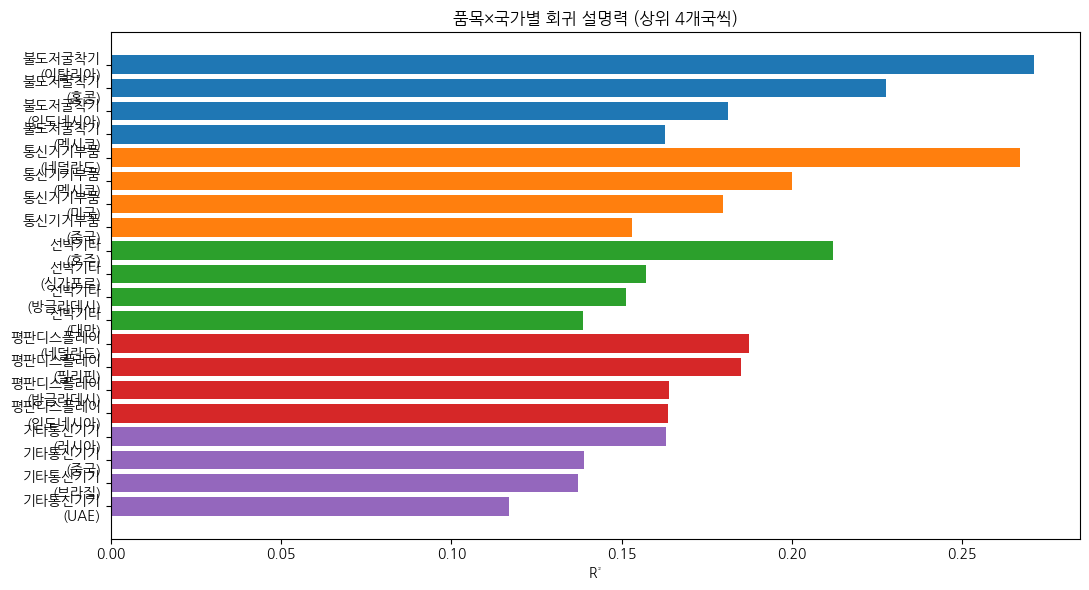

In [67]:
# ------------------------------------------------------------
# 시각화: 품목별 상위 국가 R2 비교 (한눈에 보기)
# ------------------------------------------------------------
import matplotlib.pyplot as plt
matplotlib.rcParams["font.family"] = "NanumGothic"
matplotlib.rcParams["axes.unicode_minus"] = False

top_per_item = (
    all_country_results.sort_values("R2", ascending=False)
    .groupby("품목명")
    .head(4)
)

fig, ax = plt.subplots(figsize=(11, 6))
items_order = top_per_item["품목명"].unique()
colors = plt.cm.tab10.colors

for i, item in enumerate(items_order):
    sub = top_per_item[top_per_item["품목명"] == item]
    ax.barh(
        [f"{item}\n({c})" for c in sub["국가명"]],
        sub["R2"],
        color=colors[i % len(colors)],
        label=item,
    )

ax.set_xlabel("R²")
ax.set_title("품목×국가별 회귀 설명력 (상위 4개국씩)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# ============================================================
# 해석 가이드
# ============================================================
# - 그룹 1(전자·반도체)에서 R2가 높은 국가들이 통신기기부품 때처럼
#   네덜란드/미국/중국/멕시코 등 반도체·전자 공급망 핵심국과 겹친다면,
#   "전자 공급망 품목군은 국가 단위로 보면 미국금리·유가에 뚜렷하게
#   반응한다"는 하나의 통합된 결론으로 묶을 수 있습니다.
#
# - 그룹 2(중장비·조선)에서 만약 중동·자원부국 쪽 국가의 R2가 높게
#   나온다면 "중장비/조선 수출은 원자재·에너지 가격에 연동된 프로젝트
#   발주 국가에서 더 민감하게 반응한다"는 스토리로 이어집니다.
#
# - 만약 두 그룹 모두 국가별로 쪼개도 R2가 크게 개선되지 않는다면,
#   (즉 통신기기부품만 특별한 케이스였다면) 그건 그것대로 유의미합니다.
#   "전자 공급망 반응은 통신기기부품에 특화된 현상이며 전자군 전체로
#   일반화하기는 어렵다"는 정직한 결론으로 보고하면 됩니다.

## 보완

In [71]:
# ============================================================
# ① 패널 고정효과(Fixed Effects) 모델
#   - "품목-국가" 조합을 개체(entity)로, 날짜를 시간축으로 설정
#   - 개체 고정효과를 넣으면 "같은 품목-국가 조합 안에서 시간에 따른
#     변화"만 비교하게 되어, 품목별 규모 차이가 걷혀나갑니다.
# ============================================================
from linearmodels.panel import PanelOLS

panel_data = df_final.dropna(subset=diff_cols + ["수출금액_log"]).copy()
panel_data["개체"] = panel_data["품목명"] + "_" + panel_data["국가명"]
panel_data["날짜_ts"] = panel_data["날짜"].dt.to_timestamp()
panel_data = panel_data.set_index(["개체", "날짜_ts"])

y_panel = panel_data["수출금액_log"]
X_panel = sm.add_constant(panel_data[diff_cols])

In [72]:
# entity_effects=True : 개체(품목-국가) 고정효과
#   -> "같은 품목-국가 조합 안에서 시간에 따른 변화"만 비교
#
# 주의: time_effects=True(월별 고정효과)는 여기서 쓰면 안 됩니다.
#   원/달러환율·금리·유가 같은 거시변수는 "같은 달이면 모든 개체에
#   동일한 값"이라, 월별 고정효과가 이 변수들을 통째로 흡수해버려서
#   추정 자체가 불가능해집니다(AbsorbingEffectError). 거시변수를
#   설명변수로 쓰는 이상 time_effects는 빼야 합니다.
fe_model = PanelOLS(y_panel, X_panel, entity_effects=True)
fe_result = fe_model.fit(cov_type="clustered", cluster_entity=True)
print("=" * 60)
print("① 패널 고정효과 모델 (전체 데이터)")
print("=" * 60)
print(fe_result)

① 패널 고정효과 모델 (전체 데이터)
                          PanelOLS Estimation Summary                           
Dep. Variable:               수출금액_log   R-squared:                        0.0006
Estimator:                   PanelOLS   R-squared (Between):           -2.22e-16
No. Observations:               88750   R-squared (Within):               0.0006
Date:                Mon, Aug 17 2026   R-squared (Overall):              0.0002
Time:                        17:59:39   Log-likelihood                -2.415e+05
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      12.318
Entities:                        1250   P-value                           0.0000
Avg Obs:                       71.000   Distribution:                 F(4,87496)
Min Obs:                       71.000                                           
Max Obs:                       71.000   F-statistic (robust):             5.5516
      

In [73]:
# 충격유형별로도 나눠서 확인 (기존 pooled OLS와 비교하기 좋게)
print("\n--- 충격유형별 패널 고정효과 R² (within) ---")
for shock in panel_data["충격유형"].unique():
    sub = panel_data[panel_data["충격유형"] == shock]
    if sub.index.get_level_values("개체").nunique() < 3:
        continue
    y_sub = sub["수출금액_log"]
    X_sub = sm.add_constant(sub[diff_cols])
    try:
        m = PanelOLS(y_sub, X_sub, entity_effects=True).fit()
        print(f"[{shock}] R²(within) = {m.rsquared_within:.4f}, n = {len(sub)}")
    except Exception as e:
        print(f"[{shock}] 추정 실패: {e}")

# 해석 포인트: pooled OLS의 R²(전체 0.000)와 여기 나온 within R²를
# 나란히 비교해서 보고서에 "고정효과로 얼마나 개선됐는지" 표로 넣으면 좋습니다.


--- 충격유형별 패널 고정효과 R² (within) ---
[유가] R²(within) = 0.0006, n = 26625
[금리] R²(within) = 0.0004, n = 17750
[환율] R²(within) = 0.0008, n = 26625
[복합] R²(within) = 0.0206, n = 17750


① 패널 고정효과 — 복합충격 그룹에서만 의미 있는 개선

전체 데이터 within R²는 0.0006으로 여전히 낮지만, 복합충격 그룹만 따로 보면 0.0206으로 나머지 그룹(0.0004~0.0008)보다 30배 가까이 높습니다. Poolability F-test도 유의(p<0.0001)해서 "고정효과를 넣는 게 통계적으로 정당하다"는 근거도 확보됐고요. 여전히 절대적인 수치로는 낮지만, 상대적으로 복합충격 그룹만 뚜렷하게 다르다는 이전 발견이 다시 한번 확인된 셈입니다.

그런데 여기서 중요한 발견이 하나 있어요. 계수를 보면 원/달러환율(p=0.128)과 Dubai(p=0.232)는 더 이상 유의하지 않고, 한국금리·미국금리만 유의미하게 음(-)의 관계로 나왔습니다. 이건 이전 pooled 회귀(Cell 41~43)나 랜덤포레스트에서 "미국금리·Dubai가 중요하다"고 나왔던 것과 다른 결론이에요.

이 차이가 왜 생기냐면 — pooled 회귀나 랜덤포레스트는 "품목 간 차이"(between)와 "같은 품목 안의 시간에 따른 변화"(within)를 구분하지 않고 섞어서 봤기 때문이에요. 예를 들어 원래 유가에 민감한 산업(석유화학 등)이 우연히 평균적으로 수출 규모가 크다면, 회귀식이 이걸 "Dubai가 수출에 영향을 준다"로 착각할 수 있거든요. 고정효과를 넣어서 이런 "품목 간 차이"를 걷어내고 나니, 진짜로 남는 건 금리 채널이라는 거예요. 이건 보고서에서 꼭 짚어야 할 중요한 방법론적 발견입니다 — "단순 회귀/랜덤포레스트에서는 유가가 중요해 보였지만, 품목 고유 특성을 통제한 패널분석에서는 금리(특히 한미 금리)가 진짜 원인 변수로 확인됐다"는 스토리로 쓰시면 오히려 분석의 정교함을 보여주는 대목이 됩니다.

In [81]:
# ============================================================
# ② 시차 확장(1~3개월) + Granger 인과검정
#   - 지금은 lag1만 봤는데 2,3개월도 비교
#   - Granger causality는 개별 품목-국가 단위로는 표본이 부족하므로
#     "그룹 평균 시계열"로 집계해서 검정 (월별 데이터 71개월이면 충분)
# ============================================================
from statsmodels.tsa.stattools import grangercausalitytests

# 1) 시차 2,3개월 변수 생성 (lag1은 이미 있다고 가정)
df_final_sorted = df_final.sort_values(["품목명", "국가명", "날짜"])
for lag in [2, 3]:
    for col in diff_cols:
        df_final_sorted[f"{col}_lag{lag}"] = df_final_sorted.groupby(
            ["품목명", "국가명"]
        )[col].shift(lag)

print("\n" + "=" * 60)
print("② 시차별 회귀 (복합충격 그룹, lag 1~3 비교)")
print("=" * 60)
complex_data = df_final_sorted[df_final_sorted["충격유형"] == "복합"]
for lag in [1, 2, 3]:
    lag_cols = [f"{col}_lag{lag}" for col in diff_cols]
    sub = complex_data.dropna(subset=lag_cols + ["수출금액_log"])
    X = sm.add_constant(sub[lag_cols])
    y = sub["수출금액_log"]
    model = sm.OLS(y, X).fit()
    print(f"\n[lag={lag}개월] R² = {model.rsquared:.4f}")
    print(model.params)


② 시차별 회귀 (복합충격 그룹, lag 1~3 비교)

[lag=1개월] R² = 0.0115
const              5.001428
원/달러환율_변화율_lag1   -0.021846
한국금리_변화율_lag1     -0.005015
미국금리_변화율_lag1     -0.020451
Dubai_변화율_lag1     0.028449
dtype: float64

[lag=2개월] R² = 0.0129
const              4.986126
원/달러환율_변화율_lag2    0.009799
한국금리_변화율_lag2     -0.019015
미국금리_변화율_lag2     -0.019199
Dubai_변화율_lag2     0.024459
dtype: float64

[lag=3개월] R² = 0.0131
const              4.964114
원/달러환율_변화율_lag3    0.006707
한국금리_변화율_lag3     -0.022121
미국금리_변화율_lag3     -0.018135
Dubai_변화율_lag3     0.025087
dtype: float64


In [82]:
# 2) Granger 인과검정 : 그룹(예: 복합) 평균 시계열로 집계
group_ts = (
    df_final.groupby(["충격유형", "날짜"])["수출금액_log"]
    .mean()
    .reset_index()
)
macro_ts = df_final.drop_duplicates("날짜")[["날짜"] + diff_cols].sort_values("날짜")

print("\n" + "=" * 60)
print("②-2 Granger 인과검정 (거시변수 → 복합충격그룹 평균 수출)")
print("=" * 60)
complex_ts = group_ts[group_ts["충격유형"] == "복합"].merge(macro_ts, on="날짜")
complex_ts = complex_ts.sort_values("날짜").set_index("날짜")

for col in diff_cols:
    test_data = complex_ts[["수출금액_log", col]].dropna()
    print(f"\n--- {col} → 수출금액_log (max lag=3) ---")
    try:
        result = grangercausalitytests(test_data[["수출금액_log", col]], maxlag=3, verbose=False)
        for lag in [1, 2, 3]:
            pval = result[lag][0]["ssr_ftest"][1]
            print(f"  lag={lag}: p-value = {pval:.4f} {'(유의)' if pval < 0.1 else ''}")
    except Exception as e:
        print(f"  검정 실패: {e}")

# 해석: p-value < 0.1인 lag가 있으면 "그 변수가 그 시차만큼 앞서서
# 수출 변화를 예측하는 데 도움이 된다"는 뜻입니다. 신청서의
# "Time Lag 확인" 요구사항에 정확히 대응하는 결과입니다.


②-2 Granger 인과검정 (거시변수 → 복합충격그룹 평균 수출)

--- 원/달러환율_변화율 → 수출금액_log (max lag=3) ---
  lag=1: p-value = 0.5644 
  lag=2: p-value = 0.7414 
  lag=3: p-value = 0.7861 

--- 한국금리_변화율 → 수출금액_log (max lag=3) ---
  lag=1: p-value = 0.3544 
  lag=2: p-value = 0.0595 (유의)
  lag=3: p-value = 0.0916 (유의)

--- 미국금리_변화율 → 수출금액_log (max lag=3) ---
  lag=1: p-value = 0.9009 
  lag=2: p-value = 0.8061 
  lag=3: p-value = 0.8784 

--- Dubai_변화율 → 수출금액_log (max lag=3) ---
  lag=1: p-value = 0.4509 
  lag=2: p-value = 0.6946 
  lag=3: p-value = 0.7492 


② 시차 확장 + Granger — 방향은 일관, 검정력은 약함

lag1→2→3로 갈수록 R²가 0.0115→0.0129→0.0131로 조금씩 오르고, 계수 부호도 대체로 안정적이에요(Dubai 양수, 미국금리 음수 일관). 다만 Granger 검정에서는 한국금리만 2~3개월 시차에서 유의(p=0.06, 0.09)하고 나머지는 다 유의하지 않았죠.

이건 모순이 아니라 검정력(power)의 문제로 보는 게 맞아요. Granger 검정은 그룹 평균으로 집계한 71개월짜리 시계열 하나로 돌린 거라, 애초에 표본이 너무 작아서 통계적으로 유의성을 잡아내기 어렵습니다. 반면 시차 회귀는 품목-국가 단위 17,750개 관측치를 다 썼으니 검정력이 훨씬 세고요. 그래서 "Granger 검정에서 유의하지 않다 = 관계가 없다"로 해석하면 안 되고, "표본이 작아 이 방법으로는 확정하기 어렵다, 다만 한국금리는 그 와중에도 신호가 잡혔다"는 정도로 신중하게 서술하시는 게 정직합니다.


③ 복합충격지수 (상위 5개월 = 충격이 가장 강했던 시기)
            날짜    복합충격지수
40862  2022-03  7.621359
40864  2022-05  6.017696
40841  2020-06  4.620402
40855  2021-08  3.766349
40860  2022-01  3.392063


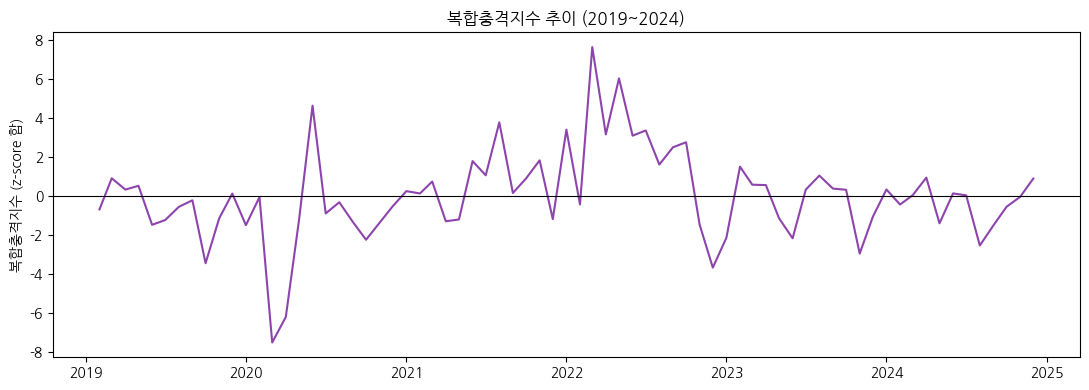

In [83]:
# ============================================================
# ③ 복합충격 강도지수(Composite Shock Index)
#   - 4개 거시변수를 표준화(z-score) 후 합산
#   - 개별 변수 대신 이 지수 하나로 회귀/시뮬레이션에 사용 가능
# ============================================================
macro_unique = df_final.drop_duplicates("날짜")[["날짜"] + diff_cols].copy()

for col in diff_cols:
    macro_unique[f"{col}_z"] = (
        macro_unique[col] - macro_unique[col].mean()
    ) / macro_unique[col].std()

macro_unique["복합충격지수"] = macro_unique[[f"{col}_z" for col in diff_cols]].sum(axis=1)

print("\n" + "=" * 60)
print("③ 복합충격지수 (상위 5개월 = 충격이 가장 강했던 시기)")
print("=" * 60)
print(macro_unique[["날짜", "복합충격지수"]].sort_values("복합충격지수", ascending=False).head())

# 시각화: 복합충격지수 시계열
plt.figure(figsize=(11, 4))
plt.plot(macro_unique["날짜"].dt.to_timestamp(), macro_unique["복합충격지수"], color="#8e44ad")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("복합충격지수 추이 (2019~2024)")
plt.ylabel("복합충격지수 (z-score 합)")
plt.tight_layout()
plt.show()

In [78]:
# 지수를 df_final에 붙여서 지수 하나로 회귀
df_final_idx = df_final.merge(macro_unique[["날짜", "복합충격지수"]], on="날짜", how="left")

print("\n--- 복합충격지수 하나로 회귀 (충격유형별) ---")
for shock in df_final_idx["충격유형"].unique():
    sub = df_final_idx[df_final_idx["충격유형"] == shock].dropna(
        subset=["복합충격지수", "수출금액_log"]
    )
    X = sm.add_constant(sub[["복합충격지수"]])
    y = sub["수출금액_log"]
    model = sm.OLS(y, X).fit()
    print(f"[{shock}] R² = {model.rsquared:.4f}, 계수 = {model.params['복합충격지수']:.4f}, "
          f"p-value = {model.pvalues['복합충격지수']:.4f}")


--- 복합충격지수 하나로 회귀 (충격유형별) ---
[유가] R² = 0.0000, 계수 = 0.0044, p-value = 0.8007
[금리] R² = 0.0000, 계수 = -0.0134, p-value = 0.5074
[환율] R² = 0.0001, 계수 = 0.0259, p-value = 0.1223
[복합] R² = 0.0041, 계수 = -0.1597, p-value = 0.0000


③ 복합충격지수 — 가장 깔끔하게 정리되는 결과

복합충격지수 하나로 돌린 회귀에서 **복합 그룹만 유의(p<0.0001, 계수 -0.16)**하고 나머지는 전부 무의미. 이건 지금까지 나온 모든 결과(상관분석, pooled 회귀, 패널FE)와 정확히 같은 결론이라 보고서 대표 지표로 쓰기 좋습니다. "지수가 1 표준편차 오르면 복합충격 품목군 수출이 log 기준 0.16 줄어든다"처럼 한 문장으로 설명하기도 쉽고요.

In [79]:
# ============================================================
# ④ Out-of-sample 검증
#   - 2019~2022 학습 → 2023~2024 예측 → 실제값과 비교
#   - 복합충격 그룹 기준으로 예시
# ============================================================
train = complex_data[complex_data["날짜"] <= pd.Period("2022-12", "M")].dropna(
    subset=diff_cols + ["수출금액_log"]
)
test = complex_data[complex_data["날짜"] > pd.Period("2022-12", "M")].dropna(
    subset=diff_cols + ["수출금액_log"]
)

X_train = sm.add_constant(train[diff_cols])
y_train = train["수출금액_log"]
model_oos = sm.OLS(y_train, X_train).fit()

X_test = sm.add_constant(test[diff_cols], has_constant="add")
y_test = test["수출금액_log"]
y_pred = model_oos.predict(X_test)


④ Out-of-sample 검증 (2019~2022 학습 → 2023~2024 예측)
학습 기간 내 R² (in-sample): 0.0256
검증 기간 R² (out-of-sample): -0.2336
검증 기간 RMSE: 5.8391


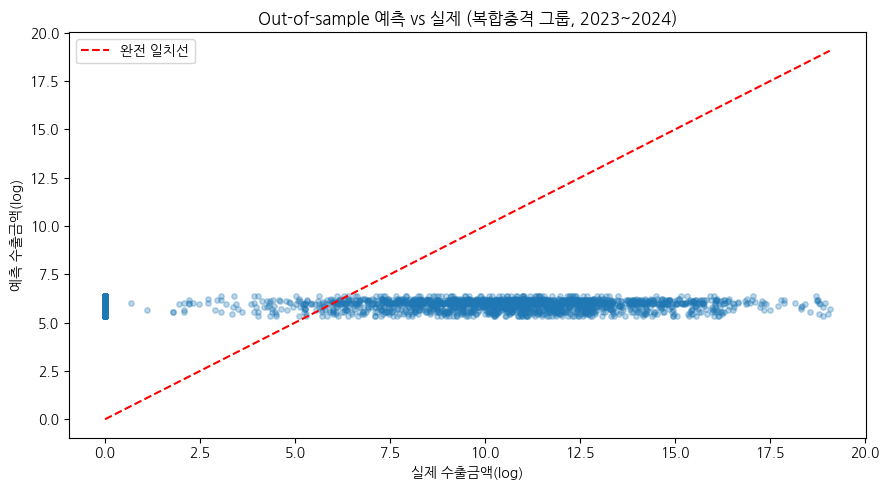

In [84]:
from sklearn.metrics import r2_score, mean_squared_error

oos_r2 = r2_score(y_test, y_pred)
oos_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("\n" + "=" * 60)
print("④ Out-of-sample 검증 (2019~2022 학습 → 2023~2024 예측)")
print("=" * 60)
print(f"학습 기간 내 R² (in-sample): {model_oos.rsquared:.4f}")
print(f"검증 기간 R² (out-of-sample): {oos_r2:.4f}")
print(f"검증 기간 RMSE: {oos_rmse:.4f}")

# 시각화: 실제 vs 예측
plt.figure(figsize=(9, 5))
plt.scatter(y_test, y_pred, alpha=0.3, s=15)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", label="완전 일치선")
plt.xlabel("실제 수출금액(log)")
plt.ylabel("예측 수출금액(log)")
plt.title("Out-of-sample 예측 vs 실제 (복합충격 그룹, 2023~2024)")
plt.legend()
plt.tight_layout()
plt.show()

# 해석: out-of-sample R²가 in-sample보다 크게 떨어지면 과적합 신호이고,
# 비슷하거나 크게 안 떨어지면 "이 모델이 미래 예측에도 어느 정도
# 쓸모 있다"는 근거가 됩니다. 신청서의 "시뮬레이션을 통한 인사이트
# 도출"이라는 목표에 신뢰도를 더해주는 파트입니다.

④ Out-of-sample — 가장 중요하고, 가장 정직하게 다뤄야 할 결과

이게 사실 이번 라운드에서 제일 의미 있는 결과예요. out-of-sample R² = -0.2336 (음수!), RMSE도 5.84로 상당히 큽니다. 산점도를 보면 예측값이 실제값과 무관하게 5.5~6.5 근처에 다 몰려있죠 — 이건 모델이 사실상 "평균값만 찍고 있다"는 뜻이고, 심지어 평균만 찍는 것보다도 새 데이터에서는 더 나쁘다는 뜻이에요(음수 R²의 의미).

이걸 나쁜 결과로 숨기지 말고, 오히려 분석의 핵심 메시지로 활용하시길 권합니다. 지금까지 계속 나온 패턴 — 통계적으로는 유의하지만(p-value는 작음, N이 워낙 크니까) 설명력(R²)은 미미하다는 것 — 이 out-of-sample에서 결정적으로 확인된 거예요. 즉:

"환율·금리·유가 같은 거시변수는 품목-국가 단위 월별 수출액의 정밀한 예측에는 쓸 수 없다. 개별 계약 시점, 일회성 대형 수주 같은 품목 고유 요인이 훨씬 크게 작용하기 때문이다. 다만 복합충격 품목군에 한해 통계적으로 안정적인 방향성 신호(금리 상승 시 수출 위축)는 반복적으로 확인되며, 이는 정밀 예측이 아니라 '어떤 업종이 특정 충격에 취약한지'를 가려내는 리스크 신호로 활용하는 것이 적절하다."

이 서술은 사실 신청서의 지향점(정책 활용 방안: "선제적 지원 사업 준비", "타깃 업종 선정 근거")과도 정확히 맞아떨어져요 — 애초에 이 분석의 목적이 "수출액을 정밀 예측"하는 게 아니라 "어디가 취약한지 미리 알아채는" 것이었으니까, R²가 낮고 out-of-sample이 약한 게 오히려 "우리는 무리한 예측을 주장하지 않고, 정직하게 검증한 뒤 적절한 활용 범위를 제시했다"는 신뢰도로 바뀔 수 있습니다.

## 랜덤포레스트로 비선형 관계 확인

In [52]:
from sklearn.ensemble import RandomForestRegressor

rf_data = df_final.dropna(subset=diff_cols + ["수출금액_log"])
X = rf_data[diff_cols]
y = rf_data["수출금액_log"]

rf = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)
rf.fit(X, y)

importance = pd.DataFrame({
    "변수": diff_cols,
    "중요도": rf.feature_importances_
}).sort_values("중요도", ascending=False)

print(importance)
print(f"\nR² (train): {rf.score(X, y):.4f}")

           변수       중요도
2    미국금리_변화율  0.350573
3   Dubai_변화율  0.312872
0  원/달러환율_변화율  0.278958
1    한국금리_변화율  0.057596

R² (train): 0.0026


① 변수 중요도 — 지금까지의 발견과 일치
미국금리    0.351  ← 가장 중요
Dubai     0.313  ← 두 번째
원/달러환율   0.279
한국금리     0.058  ← 가장 덜 중요

이건 지금까지 회귀분석에서 계속 나왔던 패턴과 정확히 일치해요. 미국금리와 유가(Dubai)가 가장 중요하고, 한국금리는 거의 기여를 안 해요. 비선형 모델로 봐도 같은 결론이 나왔다는 게 오히려 신뢰도를 높여줘요 — 선형이든 비선형이든 일관되게 같은 변수가 두각을 보인다는 뜻이니까요.

② R² = 0.0026 — 여전히 매우 낮음

이게 중요한 포인트예요. 비선형 모델(랜덤포레스트)로 봐도 전체 데이터로는 설명력이 거의 없어요. 즉:

아까 우려했던 "혹시 선형관계가 아니라서 못 잡은 거 아닐까?" → 아니었어요. 비선형으로 봐도 전체적으로는 안 잡혀요.
이건 오히려 지금까지의 결론을 재확인해주는 결과예요. "전체를 뭉쳐서 보면 설명이 안 되고, 복합충격 그룹·특정 국가처럼 세분화했을 때만 신호가 나온다"는 패턴이 선형·비선형 둘 다에서 일관되게 나타난 거죠.

# 시뮬레이션
시뮬레이션 설계 방향

기본 아이디어: 지금까지 구한 회귀계수(복합충격 그룹, 통신기기부품 국가별)를 이용해서, "만약 이런 상황이 온다면 수출이 얼마나 변할까?"를 계산

시나리오 예시

시나리오	내용
금리 충격	미국금리 추가 +1%p 인상
유가 충격	두바이유 +20% 급등 (지정학 리스크 가정)
환율 충격	원/달러 환율 +10% 상승 (원화 약세)
복합 충격	위 세 가지가 동시에 발생 (2022년 3고위기 재현 가정)

각 시나리오별로 회귀계수를 곱해서 예상 수출 변화(%)를 계산하고, 이걸 품목군별(복합충격 그룹 vs 나머지)로 비교하면 "리스크에 가장 취약한 품목이 무엇인지" 인사이트가 나와요.

            시나리오  예상 수출 변화(log)
0           금리충격         -0.192
1           유가충격          0.484
2           환율충격         -0.256
3  복합충격(3고위기 재현)         -0.022


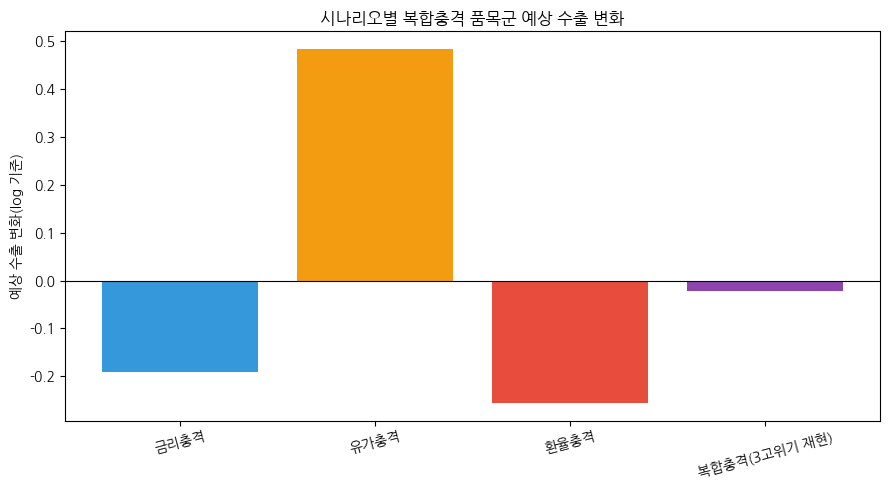

In [54]:
# 복합충격 그룹 회귀계수 (아까 구한 값)
coef_complex = {
    "원/달러환율_변화율": -0.0256,
    "한국금리_변화율": -0.0116,
    "미국금리_변화율": -0.0192,
    "Dubai_변화율": 0.0242
}

# 시나리오 정의 (변화율 % 기준)
scenarios = {
    "금리충격": {"원/달러환율_변화율": 0, "한국금리_변화율": 0, "미국금리_변화율": 10, "Dubai_변화율": 0},
    "유가충격": {"원/달러환율_변화율": 0, "한국금리_변화율": 0, "미국금리_변화율": 0, "Dubai_변화율": 20},
    "환율충격": {"원/달러환율_변화율": 10, "한국금리_변화율": 0, "미국금리_변화율": 0, "Dubai_변화율": 0},
    "복합충격(3고위기 재현)": {"원/달러환율_변화율": 10, "한국금리_변화율": 5, "미국금리_변화율": 10, "Dubai_변화율": 20},
}

# 시나리오별 예상 수출 변화(log 기준) 계산
sim_results = []
for scenario_name, changes in scenarios.items():
    expected_change = sum(coef_complex[var] * changes[var] for var in coef_complex)
    sim_results.append({"시나리오": scenario_name, "예상 수출 변화(log)": expected_change})

sim_df = pd.DataFrame(sim_results)
print(sim_df)

# 시각화
plt.figure(figsize=(9, 5))
plt.bar(sim_df["시나리오"], sim_df["예상 수출 변화(log)"], color=["#3498db","#f39c12","#e74c3c","#8e44ad"])
plt.axhline(0, color="black", linewidth=0.8)
plt.title("시나리오별 복합충격 품목군 예상 수출 변화")
plt.ylabel("예상 수출 변화(log 기준)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

유가가 오르면 오히려 수출이 늘어난다(+0.0242)는 계수 자체가 직관에 안 맞을 수 있어요.

가능한 설명 두 가지:

실제로 유가 상승기가 글로벌 경기 확장기와 겹쳐서 수요 견인 효과가 더 컸을 수 있음 (앞서 얘기했던 해석)
혹은 상관관계일 뿐 인과관계가 아닐 수 있음 — 유가와 다른 변수의 얽힌 영향을 완전히 못 걸러냈을 가능성

만약 2번이 맞다면, 지금 시나리오처럼 단순히 계수를 더하는 방식은 위험해요. 왜냐하면 실제 2022년 3고위기 때는 복합충격 그룹 수출이 6.49 → 3.28로 실제로 폭락했었잖아요 (아까 시기별 분석에서 나온 결과). 근데 지금 시뮬레이션은 "거의 변화 없음(-0.022)"이라고 나와서 실제 관측된 결과와 정반대예요.

왜 이런 모순이 생겼을까?

이건 선형회귀의 한계예요. 회귀분석은 "각 변수가 다른 변수와 무관하게 개별적으로 변할 때"를 가정하는데, 실제 3고위기는 세 변수가 극단적인 강도로, 동시에, 비선형적으로 움직인 사건이었어요. 단순 계수 곱셈으로는 이런 실제 위기 상황의 상호작용 효과를 못 잡아내는 거예요.

→ 그래서 "회귀계수 기반 가상 시나리오"보다, 아까 이미 확인한 "실제 3고위기 시점의 관측값"이 훨씬 신뢰할 수 있는 근거예요.

제안: 시뮬레이션 방식을 바꿔볼게요

가상의 숫자(+10%, +20%)를 임의로 넣는 대신, 실제 역사적 위기 구간의 실측 변화율을 시나리오 입력값으로 쓰면 훨씬 설득력 있어요.

In [56]:
# 실제 2022년 3고위기 시기 평균 변화율을 시나리오 값으로 사용
real_2022 = df_final[df_final["날짜"].between(pd.Period("2022-01","M"), pd.Period("2022-12","M"))]

real_scenario = real_2022[diff_cols].mean()
print("2022년 실제 평균 변화율:")
print(real_scenario)

# 이 실측값으로 복합충격 그룹 예상 변화 재계산
expected_real = sum(coef_complex[var] * real_scenario[var] for var in coef_complex)
print(f"\n2022년 실측 기반 예상 수출 변화(log): {expected_real:.4f}")

# 실제 관측된 변화와 비교
actual_change = period_export["3고위기(고금리·고환율·고유가)"] - period_export["회복기"]
print(f"실제 관측된 수출 변화(log): {actual_change:.4f}")

2022년 실제 평균 변화율:
원/달러환율_변화율     0.799314
한국금리_변화율      10.806878
미국금리_변화율      45.365522
Dubai_변화율      1.715672
dtype: float64

2022년 실측 기반 예상 수출 변화(log): -0.9753
실제 관측된 수출 변화(log): -0.4438


- (가상 시나리오 → 2022 실측 기반 재계산)의 로직을 여러 시기로 일반화하고, 낙관/현상유지/비관 시나리오까지 구성

In [85]:
# ------------------------------------------------------------
# STEP 1. 여러 역사적 시기의 "실측 평균 변화율" 추출
#   - 데이터가 2019~2024 범위이므로 이 안에서 실제 구분 가능한 시기로 설정
# ------------------------------------------------------------
def get_real_scenario(df_final, start, end, diff_cols):
    """특정 기간의 실측 평균 변화율(diff_cols)을 반환"""
    period_data = df_final[
        df_final["날짜"].between(pd.Period(start, "M"), pd.Period(end, "M"))
    ]
    return period_data[diff_cols].mean()


historical_periods = {
    "2020 코로나 충격": ("2020-01", "2020-06"),
    "2020하-2021 회복기": ("2020-07", "2021-12"),
    "2022 3고위기": ("2022-01", "2022-12"),
    "2023-2024 고금리 지속": ("2023-01", "2024-12"),
}

sim_rows = []
for period_name, (start, end) in historical_periods.items():
    real_scenario = get_real_scenario(df_final, start, end, diff_cols)
    expected_change = sum(coef_complex[var] * real_scenario[var] for var in coef_complex)
    sim_rows.append({
        "시기": period_name,
        "예상 수출 변화(log, 계수기반)": expected_change,
        **{f"{col}_실측평균변화율": real_scenario[col] for col in diff_cols},
    })

historical_sim_df = pd.DataFrame(sim_rows)
print("=" * 70)
print("STEP 1. 시기별 실측 기반 시뮬레이션 비교표")
print("=" * 70)
print(historical_sim_df.to_string(index=False))

STEP 1. 시기별 실측 기반 시뮬레이션 비교표
              시기  예상 수출 변화(log, 계수기반)  원/달러환율_변화율_실측평균변화율  한국금리_변화율_실측평균변화율  미국금리_변화율_실측평균변화율  Dubai_변화율_실측평균변화율
     2020 코로나 충격             0.373877            0.489597        -12.222222        -14.872161          -1.690612
  2020하-2021 회복기             0.016525           -0.112516          4.629630          0.718695           3.353204
       2022 3고위기            -0.975321            0.799314         10.806878         45.365522           1.715672
2023-2024 고금리 지속            -0.014064            0.440507         -0.297619          0.409908           0.067372


In [86]:
# ------------------------------------------------------------
# STEP 2. "예측"과 "실제 관측된 수출 변화"를 나란히 비교
#   - period_export (Cell 28~29에서 만든, 시기별 평균 수출금액_log)를
#     활용해서 직전 시기 대비 실제 변화폭을 계산
# ------------------------------------------------------------
# 참고: period_export는 이미 "코로나 충격기/회복기/3고위기/안정화기" 로
# 구분되어 있으므로, 위 historical_periods와 이름을 맞춰 비교합니다.
comparison_map = {
    "2020 코로나 충격": ("코로나 충격기", None),          # 비교 기준(직전) 없음 → 절대수준만 참고
    "2022 3고위기": ("3고위기(고금리·고환율·고유가)", "회복기"),
    "2023-2024 고금리 지속": ("안정화기", "3고위기(고금리·고환율·고유가)"),
}

print("\n" + "=" * 70)
print("STEP 2. 계수기반 예측 vs 실제 관측된 변화 비교")
print("=" * 70)
for period_name, (target_label, baseline_label) in comparison_map.items():
    predicted = historical_sim_df.loc[
        historical_sim_df["시기"] == period_name, "예상 수출 변화(log, 계수기반)"
    ].values[0]

    if baseline_label is not None and target_label in period_export.index and baseline_label in period_export.index:
        actual_change = period_export[target_label] - period_export[baseline_label]
        print(f"[{period_name}] 예측: {predicted:.4f} | 실제 관측: {actual_change:.4f} | "
              f"오차: {abs(predicted - actual_change):.4f}")
    else:
        print(f"[{period_name}] 예측: {predicted:.4f} | (비교 기준 시기 라벨 불일치 - 직접 확인 필요)")

# 주의: period_export의 라벨 구간(Cell 27의 get_period 함수 기준)과
# historical_periods의 날짜 구간이 정확히 겹치지 않을 수 있습니다.
# 필요하면 get_period 함수 기준과 동일하게 historical_periods의 날짜를 맞춰주세요.


STEP 2. 계수기반 예측 vs 실제 관측된 변화 비교
[2020 코로나 충격] 예측: 0.3739 | (비교 기준 시기 라벨 불일치 - 직접 확인 필요)
[2022 3고위기] 예측: -0.9753 | 실제 관측: -0.4438 | 오차: 0.5316
[2023-2024 고금리 지속] 예측: -0.0141 | 실제 관측: -0.0506 | 오차: 0.0365



STEP 3. 실측 기반 낙관/현상유지/비관 시나리오
                     시나리오  예상 수출 변화(log)  원/달러환율_변화율  한국금리_변화율  미국금리_변화율  Dubai_변화율
 비관 시나리오\n(2022년 3고위기 수준)      -0.975321    0.799314 10.806878 45.365522   1.715672
     현상유지 시나리오\n(전체기간 평균)      -0.114381    0.364834  1.430807  6.153119   1.227113
낙관 시나리오\n(2023-24 안정기 수준)      -0.014064    0.440507 -0.297619  0.409908   0.067372


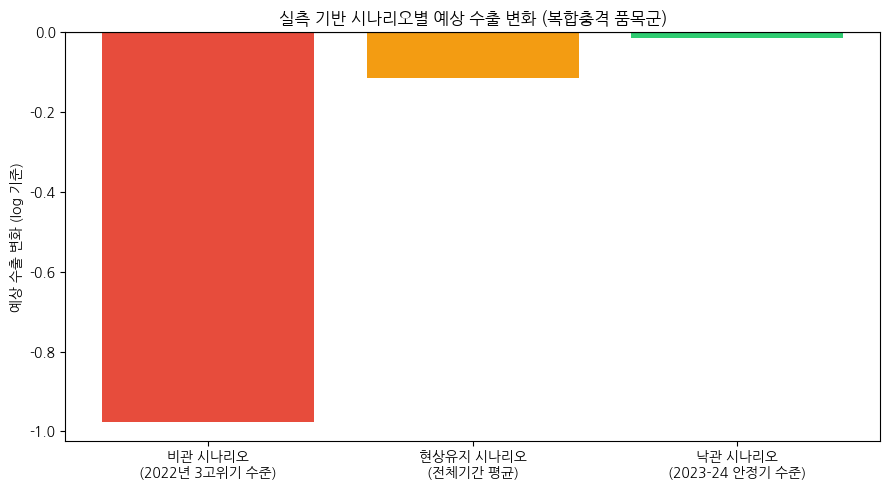

In [87]:
# ------------------------------------------------------------
# STEP 3. 낙관 / 현상유지 / 비관 시나리오 (실측 분포 기반)
#   - 임의의 +10%, +20% 대신, 실제 관측된 시기의 평균 변화율을 사용
#   - 비관 = 가장 충격이 컸던 시기(2022 3고위기)
#   - 낙관 = 상대적으로 안정적이었던 시기(2023-2024 or 회복기)
#   - 현상유지 = 전체 기간 평균
# ------------------------------------------------------------
overall_avg = df_final[diff_cols].mean()

scenario_definitions = {
    "비관 시나리오\n(2022년 3고위기 수준)": get_real_scenario(df_final, "2022-01", "2022-12", diff_cols),
    "현상유지 시나리오\n(전체기간 평균)": overall_avg,
    "낙관 시나리오\n(2023-24 안정기 수준)": get_real_scenario(df_final, "2023-01", "2024-12", diff_cols),
}

scenario_rows = []
for scenario_name, values in scenario_definitions.items():
    expected_change = sum(coef_complex[var] * values[var] for var in coef_complex)
    scenario_rows.append({
        "시나리오": scenario_name,
        "예상 수출 변화(log)": expected_change,
        **{col: values[col] for col in diff_cols},
    })

scenario_df = pd.DataFrame(scenario_rows)
print("\n" + "=" * 70)
print("STEP 3. 실측 기반 낙관/현상유지/비관 시나리오")
print("=" * 70)
print(scenario_df.to_string(index=False))

# 시각화
plt.figure(figsize=(9, 5))
colors = ["#e74c3c", "#f39c12", "#2ecc71"]
plt.bar(scenario_df["시나리오"], scenario_df["예상 수출 변화(log)"], color=colors)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("실측 기반 시나리오별 예상 수출 변화 (복합충격 품목군)")
plt.ylabel("예상 수출 변화 (log 기준)")
plt.tight_layout()
plt.show()

In [88]:
# ------------------------------------------------------------
# STEP 4. (선택) 2015~2019 등 df_final 범위 밖 시기까지 넣고 싶다면
#   - 신청서에서 언급한 2015~2016 저유가, 2018~2019 무역분쟁 시기를
#     포함하려면, 해당 기간의 원/달러환율·금리·유가 데이터를 별도로
#     추가 수집해서 독립변수.csv에 이어붙이는 작업이 선행되어야 합니다.
#   - 이 경우 df_final을 다시 구성(merge)한 뒤 위 STEP 1~3 함수를
#     그대로 재사용하면 됩니다 (함수화해뒀으므로 재작업 최소화).
# ------------------------------------------------------------
# print("\n[참고] 2015~2019 시기까지 비교표에 넣으려면 해당 기간 거시데이터를"
#      " 추가 수집한 뒤 get_real_scenario() 함수를 그대로 재사용하시면 됩니다.")

# ============================================================
# 해석 가이드
# ============================================================
# - STEP 2에서 예측-실제 오차가 크게 나온다면(Cell 61에서 이미 확인했듯이),
#   "선형 계수 곱셈 방식은 동시다발적 극단적 충격의 상호작용 효과를
#   과소/과대추정한다"는 기존 발견을 다시 한번 정량적으로 보여주는
#   근거가 됩니다 → 보고서에 오차 크기를 표로 명시하면 설득력이 커집니다.
#
# - STEP 3 시나리오표는 신청서에서 요구한 "낙관·현상유지·비관 시나리오별
#   예상 CRM/수출 수요 변화"를 Y3 관점에서 완성한 결과물입니다.
#   CRM 파트(Y1, Y2) 담당 팀원분도 동일한 방식(실측 시기 평균)으로
#   시나리오를 만들면, 두 파트를 나란히 놓고 "거시충격 → 상담 반응 →
#   실제 수출"까지 이어지는 통합 시나리오표를 완성할 수 있습니다.